In [1]:
import pandas as pd 
import numpy as np  

df=pd.read_excel("data/raw/online_retail.xlsx",sheet_name=None)
df.keys()

dict_keys(['Year 2009-2010', 'Year 2010-2011'])

In [2]:
df.keys()

dict_keys(['Year 2009-2010', 'Year 2010-2011'])

In [3]:
df_2009 = df["Year 2009-2010"]
df_2010 = df["Year 2010-2011"]

print(df_2009.shape)
print(df_2010.shape)

(525461, 8)
(541910, 8)


In [4]:
df_retail = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

print(df_retail.shape)

(1067371, 8)


In [5]:
df_retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [6]:
df_retail['Invoice'].unique()

array([489434, 489435, 489436, ..., 581585, 581586, 581587],
      shape=(53628,), dtype=object)

In [7]:
df_retail.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [8]:
df_retail.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [9]:
df_retail.duplicated().sum()


np.int64(34335)

In [10]:
df_retail.shape

(1067371, 8)

In [11]:
import matplotlib.pyplot as plt 
import seaborn as sns


In [12]:
Revenue=df_retail['Price']*df_retail['Quantity']

In [13]:
Revenue.sum()

np.float64(19287250.568)

In [14]:
df_retail.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


<Axes: xlabel='Price', ylabel='Customer ID'>

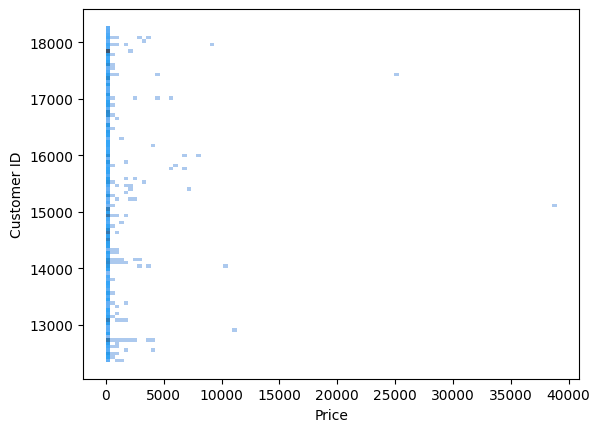

In [15]:
sns.histplot(data=df_retail, x='Price', y='Customer ID', bins=100)

In [16]:
high_price=df_retail.groupby('Price')["Customer ID"].max()

In [17]:
high_price

Price
-53594.36        NaN
-44031.79        NaN
-38925.87        NaN
-11062.06        NaN
 0.00        18071.0
              ...   
 16888.02        NaN
 17836.46        NaN
 18910.69        NaN
 25111.09    17399.0
 38970.00    15098.0
Name: Customer ID, Length: 2807, dtype: float64

In [18]:
df_retail.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='object')

In [19]:
retail = df_retail.rename(columns={
    'Customer ID': 'CustomerID',
    'InvoiceDate': 'InvoiceDate',
    'Price': 'UnitPrice'
})

In [20]:
retail.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [21]:
retail = retail.dropna(subset=['CustomerID'])

In [22]:
retail['CustomerID'].isnull().sum()

np.int64(0)

In [23]:
retail['Quantity'].describe()

count    824364.000000
mean         12.414574
std         188.976099
min      -80995.000000
25%           2.000000
50%           5.000000
75%          12.000000
max       80995.000000
Name: Quantity, dtype: float64

In [24]:
(retail['Quantity']<0).sum()

np.int64(18744)

In [25]:
purchases = retail[
    (retail['Quantity'] > 0) &
    (retail['UnitPrice'] > 0)
].copy()

In [26]:
purchases.shape

(805549, 8)

In [27]:
purchases

,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
...,...,...,...,...,...,...,...,...
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [28]:
purchases['Revenue'] = (
    purchases['Quantity'] *
    purchases['UnitPrice']
)

In [29]:
purchases[['Quantity', 'UnitPrice', 'Revenue']].head()

,Quantity,UnitPrice,Revenue
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


In [30]:
customer_revenue = purchases.groupby('CustomerID')['Revenue'].sum().reset_index()

In [31]:
customer_revenue = customer_revenue.rename(columns={'Revenue': 'TotalRevenue'})

In [32]:
customer_revenue

,CustomerID,TotalRevenue
0,12346.0,77556.46
1,12347.0,5633.32
2,12348.0,2019.40
3,12349.0,4428.69
4,12350.0,334.40
...,...,...
5873,18283.0,2736.65
5874,18284.0,461.68
5875,18285.0,427.00
5876,18286.0,1296.43


In [33]:
total_revenue = customer_revenue['TotalRevenue'].sum()

In [34]:
customer_order= purchases.groupby('CustomerID')['Invoice'].nunique().reset_index()

In [35]:
customer_order=customer_order.rename(columns={'Invoice':'TotalOrders'})

In [36]:
customer_quantity=purchases.groupby('CustomerID')['Quantity'].sum().reset_index()

In [37]:
customer_quantity=customer_quantity.rename(columns={'Quantity':'TotalQuantity'})

In [38]:
customer_product=purchases.groupby('CustomerID')['StockCode'].nunique().reset_index()

In [39]:
customer_product=customer_product.rename(columns={'StockCode':'TotalProducts'})

In [40]:
first_purchase = purchases.groupby('CustomerID')['InvoiceDate'].min().reset_index()

In [41]:
first_purchase=first_purchase.rename(columns={'InvoiceDate':'FirstPurchaseDate'})

In [42]:
last_purchase = purchases.groupby('CustomerID')['InvoiceDate'].max().reset_index()

In [43]:
last_purchase=last_purchase.rename(columns={'InvoiceDate':'LastPurchaseDate'})

In [44]:
customer_df = customer_revenue

customer_df = customer_df.merge(
    customer_order,
    on='CustomerID',
    how='left'
)

customer_df = customer_df.merge(
    customer_quantity,
    on='CustomerID',
    how='left'
)

customer_df = customer_df.merge(
    customer_product,
    on='CustomerID',
    how='left'
)

customer_df = customer_df.merge(
    first_purchase,
    on='CustomerID',
    how='left'
)

customer_df = customer_df.merge(
    last_purchase,
    on='CustomerID',
    how='left'
)


In [45]:
customer_df


,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00
1,12347.0,5633.32,8,3286,126,2010-10-31 14:20:00,2011-12-07 15:52:00
2,12348.0,2019.40,5,2714,25,2010-09-27 14:59:00,2011-09-25 13:13:00
3,12349.0,4428.69,4,1624,138,2010-04-29 13:20:00,2011-11-21 09:51:00
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00
...,...,...,...,...,...,...,...
5873,18283.0,2736.65,22,1733,352,2010-02-19 17:16:00,2011-12-06 12:02:00
5874,18284.0,461.68,1,494,28,2010-10-04 11:33:00,2010-10-04 11:33:00
5875,18285.0,427.00,1,145,12,2010-02-17 10:24:00,2010-02-17 10:24:00
5876,18286.0,1296.43,2,608,67,2009-12-16 10:45:00,2010-08-20 11:57:00


In [46]:
customer_df['AverageOrderValue'] = (
    customer_df['TotalRevenue'] /
    customer_df['TotalOrders']
)


In [47]:
analysis_date=purchases['InvoiceDate'].max() 

In [48]:
analysis_date

Timestamp('2011-12-09 12:50:00')

In [49]:
customer_df['customerTenureDays']=(analysis_date - customer_df['FirstPurchaseDate']).dt.days

In [50]:
customer_df['RecencyDays'] = (analysis_date - customer_df['LastPurchaseDate']).dt.days

In [51]:
print(customer_df.columns.tolist())

['CustomerID', 'TotalRevenue', 'TotalOrders', 'TotalQuantity', 'TotalProducts', 'FirstPurchaseDate', 'LastPurchaseDate', 'AverageOrderValue', 'customerTenureDays', 'RecencyDays']


In [52]:
print(customer_df[['FirstPurchaseDate', 'customerTenureDays']].head())

    FirstPurchaseDate  customerTenureDays
0 2009-12-14 08:34:00                 725
1 2010-10-31 14:20:00                 403
2 2010-09-27 14:59:00                 437
3 2010-04-29 13:20:00                 588
4 2011-02-02 16:01:00                 309


In [53]:
customer_df['PurchaseFrequency'] = (
    customer_df['TotalOrders'] / customer_df['customerTenureDays']
).clip(lower=1)

In [54]:
print(customer_df.columns.tolist())

['CustomerID', 'TotalRevenue', 'TotalOrders', 'TotalQuantity', 'TotalProducts', 'FirstPurchaseDate', 'LastPurchaseDate', 'AverageOrderValue', 'customerTenureDays', 'RecencyDays', 'PurchaseFrequency']


In [55]:
customer_country = (
    purchases
    .groupby('CustomerID')['Country']
    .first()
    .reset_index()
)

In [56]:
customer_df = customer_df.merge(
    customer_country,
    on='CustomerID',
    how='left'
)


In [57]:
customer_df.shape

(5878, 12)

In [58]:
customer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5878 entries, 0 to 5877
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   CustomerID          5878 non-null   float64       
 1   TotalRevenue        5878 non-null   float64       
 2   TotalOrders         5878 non-null   int64         
 3   TotalQuantity       5878 non-null   int64         
 4   TotalProducts       5878 non-null   int64         
 5   FirstPurchaseDate   5878 non-null   datetime64[ns]
 6   LastPurchaseDate    5878 non-null   datetime64[ns]
 7   AverageOrderValue   5878 non-null   float64       
 8   customerTenureDays  5878 non-null   int64         
 9   RecencyDays         5878 non-null   int64         
 10  PurchaseFrequency   5878 non-null   float64       
 11  Country             5878 non-null   object        
dtypes: datetime64[ns](2), float64(4), int64(5), object(1)
memory usage: 551.2+ KB


In [59]:
customer_df.head()

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency,Country
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,725,325,1.0,United Kingdom
1,12347.0,5633.32,8,3286,126,2010-10-31 14:20:00,2011-12-07 15:52:00,704.165000,403,1,1.0,Iceland
2,12348.0,2019.40,5,2714,25,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,437,74,1.0,Finland
3,12349.0,4428.69,4,1624,138,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,588,18,1.0,Italy
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,309,309,1.0,Norway


In [60]:
customer_df.describe()

c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency
count,5878.000000,5878.000000,5878.000000,5878.000000,5878.000000,5878,5878,5878.000000,5878.000000,5878.000000,5878.0
mean,15315.313542,3018.616737,6.289384,1821.396223,81.989112,2010-08-22 06:57:33.297039616,2011-05-22 16:19:59.469207296,391.726538,473.711637,200.331916,inf
min,12346.000000,2.950000,1.000000,1.000000,1.000000,2009-12-01 07:45:00,2009-12-01 09:55:00,2.950000,0.000000,0.000000,1.0
25%,13833.250000,348.762500,1.000000,190.000000,19.000000,2010-02-09 14:01:15,2010-11-25 10:24:45,181.652500,312.000000,25.000000,1.0
50%,15314.500000,898.915000,3.000000,491.500000,45.000000,2010-06-27 13:31:30,2011-09-05 11:59:00,285.070500,529.000000,95.000000,1.0
75%,16797.750000,2307.090000,7.000000,1376.000000,103.000000,2011-01-30 14:30:15,2011-11-14 11:31:15,420.570000,667.000000,379.000000,1.0
max,18287.000000,608821.650000,398.000000,367193.000000,2550.000000,2011-12-09 12:16:00,2011-12-09 12:50:00,84236.250000,738.000000,738.000000,inf
std,1715.572666,14737.731040,13.009406,8963.011855,116.484552,NaN,NaN,1215.071054,223.098342,209.338707,NaN


In [61]:
returns=retail[retail['Quantity']<0].copy()


In [62]:
returns.shape

(18744, 8)

In [63]:
returns.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [64]:
returns["ReturnedQuantity"]=returns['Quantity'].abs()

In [65]:
customer_returns=returns.groupby('CustomerID')['ReturnedQuantity'].sum().reset_index()

In [66]:
customer_returns=customer_returns.rename(columns={'ReturnedQuantity':'TotalReturnedQuantity'})

In [67]:
customer_returns.head()

,CustomerID,TotalReturnedQuantity
0,12346.0,74233
1,12349.0,5
2,12352.0,66
3,12359.0,226
4,12360.0,1


In [68]:
customer_df = customer_df.merge(
    customer_returns,
    on='CustomerID',
    how='left'
)

In [69]:
customer_df

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency,Country,TotalReturnedQuantity
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,725,325,1.0,United Kingdom,74233.0
1,12347.0,5633.32,8,3286,126,2010-10-31 14:20:00,2011-12-07 15:52:00,704.165000,403,1,1.0,Iceland,NaN
2,12348.0,2019.40,5,2714,25,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,437,74,1.0,Finland,NaN
3,12349.0,4428.69,4,1624,138,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,588,18,1.0,Italy,5.0
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,309,309,1.0,Norway,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5873,18283.0,2736.65,22,1733,352,2010-02-19 17:16:00,2011-12-06 12:02:00,124.393182,657,3,1.0,United Kingdom,NaN
5874,18284.0,461.68,1,494,28,2010-10-04 11:33:00,2010-10-04 11:33:00,461.680000,431,431,1.0,United Kingdom,1.0
5875,18285.0,427.00,1,145,12,2010-02-17 10:24:00,2010-02-17 10:24:00,427.000000,660,660,1.0,United Kingdom,NaN
5876,18286.0,1296.43,2,608,67,2009-12-16 10:45:00,2010-08-20 11:57:00,648.215000,723,476,1.0,United Kingdom,16.0


In [70]:
customer_df['TotalReturnedQuantity'] = customer_df['TotalReturnedQuantity'].fillna(0)   

In [71]:
customer_df['ReturnOrderRate'] = (
    customer_df['TotalReturnedQuantity'] /
    customer_df['TotalOrders']
)

In [72]:
customer_df.head(5)

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency,Country,TotalReturnedQuantity,ReturnOrderRate
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,725,325,1.0,United Kingdom,74233.0,6186.083333
1,12347.0,5633.32,8,3286,126,2010-10-31 14:20:00,2011-12-07 15:52:00,704.165000,403,1,1.0,Iceland,0.0,0.000000
2,12348.0,2019.40,5,2714,25,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,437,74,1.0,Finland,0.0,0.000000
3,12349.0,4428.69,4,1624,138,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,588,18,1.0,Italy,5.0,1.250000
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,309,309,1.0,Norway,0.0,0.000000


In [73]:
customer_df.shape

(5878, 14)

In [74]:
customer_df.head(10)

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency,Country,TotalReturnedQuantity,ReturnOrderRate
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,725,325,1.0,United Kingdom,74233.0,6186.083333
1,12347.0,5633.32,8,3286,126,2010-10-31 14:20:00,2011-12-07 15:52:00,704.165000,403,1,1.0,Iceland,0.0,0.000000
2,12348.0,2019.40,5,2714,25,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,437,74,1.0,Finland,0.0,0.000000
3,12349.0,4428.69,4,1624,138,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,588,18,1.0,Italy,5.0,1.250000
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,309,309,1.0,Norway,0.0,0.000000
5,12351.0,300.93,1,261,21,2010-11-29 15:23:00,2010-11-29 15:23:00,300.930000,374,374,1.0,Unspecified,0.0,0.000000
6,12352.0,2849.84,10,724,70,2010-11-12 10:20:00,2011-11-03 14:37:00,284.984000,392,35,1.0,Norway,66.0,6.600000
7,12353.0,406.76,2,212,23,2010-10-27 12:44:00,2011-05-19 17:47:00,203.380000,408,203,1.0,Bahrain,0.0,0.000000
8,12354.0,1079.40,1,530,58,2011-04-21 13:11:00,2011-04-21 13:11:00,1079.400000,231,231,1.0,Spain,0.0,0.000000
9,12355.0,947.61,2,543,35,2010-05-21 11:59:00,2011-05-09 13:49:00,473.805000,567,213,1.0,Bahrain,0.0,0.000000


In [75]:
customer_returns = (
    returns
    .groupby('CustomerID')['Invoice']
    .nunique()
    .reset_index()
    .rename(columns={
        'Invoice': 'ReturnOrders'
    })
)

In [76]:
customer_returns.head()

,CustomerID,ReturnOrders
0,12346.0,5
1,12349.0,1
2,12352.0,3
3,12359.0,4
4,12360.0,1


In [77]:
customer_df = customer_df.drop(
    columns=['ReturnOrderRate'],
    errors='ignore'
)

In [78]:
customer_df = customer_df.merge(
    customer_returns,
    on='CustomerID',
    how='left'
)

In [79]:
customer_df

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency,Country,TotalReturnedQuantity,ReturnOrders
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,725,325,1.0,United Kingdom,74233.0,5.0
1,12347.0,5633.32,8,3286,126,2010-10-31 14:20:00,2011-12-07 15:52:00,704.165000,403,1,1.0,Iceland,0.0,NaN
2,12348.0,2019.40,5,2714,25,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,437,74,1.0,Finland,0.0,NaN
3,12349.0,4428.69,4,1624,138,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,588,18,1.0,Italy,5.0,1.0
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,309,309,1.0,Norway,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5873,18283.0,2736.65,22,1733,352,2010-02-19 17:16:00,2011-12-06 12:02:00,124.393182,657,3,1.0,United Kingdom,0.0,NaN
5874,18284.0,461.68,1,494,28,2010-10-04 11:33:00,2010-10-04 11:33:00,461.680000,431,431,1.0,United Kingdom,1.0,1.0
5875,18285.0,427.00,1,145,12,2010-02-17 10:24:00,2010-02-17 10:24:00,427.000000,660,660,1.0,United Kingdom,0.0,NaN
5876,18286.0,1296.43,2,608,67,2009-12-16 10:45:00,2010-08-20 11:57:00,648.215000,723,476,1.0,United Kingdom,16.0,1.0


In [80]:
customer_df['ReturnOrders'] = (
    customer_df['ReturnOrders'].fillna(0)
)

In [81]:
customer_df['ReturnOrderRate'] = (
    customer_df['ReturnOrders'] /
    customer_df['TotalOrders']
)

In [82]:
customer_df['PurchaseFrequency'] = (
    customer_df['TotalOrders'] /
    (customer_df['customerTenureDays'] / 30).clip(lower=1)
)

In [83]:
customer_df[
    customer_df['CustomerID'] == 12346
]

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency,Country,TotalReturnedQuantity,ReturnOrders,ReturnOrderRate
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,725,325,0.496552,United Kingdom,74233.0,5.0,0.416667


In [84]:
retail[
    retail['CustomerID'] == 12346
][
    [
        'Invoice',
        'StockCode',
        'Quantity',
        'UnitPrice',
        'InvoiceDate'
    ]
].sort_values('InvoiceDate')

,Invoice,StockCode,Quantity,UnitPrice,InvoiceDate
27994,491725,TEST001,10,4.50,2009-12-14 08:34:00
28251,491742,TEST001,5,4.50,2009-12-14 11:00:00
28254,491744,TEST001,5,4.50,2009-12-14 11:02:00
39398,492718,TEST001,5,4.50,2009-12-18 10:47:00
39411,492722,TEST002,1,1.00,2009-12-18 10:55:00
45228,493410,TEST001,5,4.50,2010-01-04 09:24:00
45230,493412,TEST001,5,4.50,2010-01-04 09:53:00
56117,494450,TEST001,5,4.50,2010-01-14 13:50:00
66084,495295,TEST001,5,4.50,2010-01-22 13:30:00
71080,C495800,ADJUST,-1,103.50,2010-01-26 17:27:00


In [85]:
customer_df['ReturnOrderRate'].describe()

count    5878.000000
mean        0.192717
std         0.335205
min         0.000000
25%         0.000000
50%         0.000000
75%         0.279444
max         4.000000
Name: ReturnOrderRate, dtype: float64

In [86]:
customer_df[
    customer_df['ReturnOrderRate'] > 1
].shape

(85, 15)

In [87]:
customer_df['PurchaseFrequency'].describe()

count    5878.000000
mean        0.454673
std         0.655447
min         0.040650
25%         0.122324
50%         0.259740
75%         0.535714
max        16.178862
Name: PurchaseFrequency, dtype: float64

In [88]:
customer_df.isnull().sum()

CustomerID               0
TotalRevenue             0
TotalOrders              0
TotalQuantity            0
TotalProducts            0
FirstPurchaseDate        0
LastPurchaseDate         0
AverageOrderValue        0
customerTenureDays       0
RecencyDays              0
PurchaseFrequency        0
Country                  0
TotalReturnedQuantity    0
ReturnOrders             0
ReturnOrderRate          0
dtype: int64

In [89]:
customer_df['CustomerID'].duplicated().sum()

np.int64(0)

In [90]:
customer_df[
    (customer_df['TotalRevenue'] < 0) |
    (customer_df['TotalOrders'] <= 0) |
    (customer_df['TotalQuantity'] <= 0) |
    (customer_df['AverageOrderValue'] <= 0)
].shape

(0, 15)

------------------------------------Featue---Engenring------RFM-------------------------

In [91]:
customer_df.columns

Index(['CustomerID', 'TotalRevenue', 'TotalOrders', 'TotalQuantity',
       'TotalProducts', 'FirstPurchaseDate', 'LastPurchaseDate',
       'AverageOrderValue', 'customerTenureDays', 'RecencyDays',
       'PurchaseFrequency', 'Country', 'TotalReturnedQuantity', 'ReturnOrders',
       'ReturnOrderRate'],
      dtype='object')

In [92]:
customer_df[
    [
        'CustomerID',
        'TotalRevenue',
        'TotalOrders',
        'RecencyDays'

    ]
]

,CustomerID,TotalRevenue,TotalOrders,RecencyDays
0,12346.0,77556.46,12,325
1,12347.0,5633.32,8,1
2,12348.0,2019.40,5,74
3,12349.0,4428.69,4,18
4,12350.0,334.40,1,309
...,...,...,...,...
5873,18283.0,2736.65,22,3
5874,18284.0,461.68,1,431
5875,18285.0,427.00,1,660
5876,18286.0,1296.43,2,476


In [93]:
rfm=customer_df[
    [
        'CustomerID',
        'TotalRevenue',
        'TotalOrders',
        'RecencyDays'

    ]
].copy()

In [94]:
rfm

,CustomerID,TotalRevenue,TotalOrders,RecencyDays
0,12346.0,77556.46,12,325
1,12347.0,5633.32,8,1
2,12348.0,2019.40,5,74
3,12349.0,4428.69,4,18
4,12350.0,334.40,1,309
...,...,...,...,...
5873,18283.0,2736.65,22,3
5874,18284.0,461.68,1,431
5875,18285.0,427.00,1,660
5876,18286.0,1296.43,2,476


In [95]:
rfm=rfm.rename(columns={
    'TotalRevenue': 'Monetary',
    'TotalOrders': 'Frequency'}) 

In [96]:
rfm.head()

,CustomerID,Monetary,Frequency,RecencyDays
0,12346.0,77556.46,12,325
1,12347.0,5633.32,8,1
2,12348.0,2019.40,5,74
3,12349.0,4428.69,4,18
4,12350.0,334.40,1,309


In [97]:
rfm[['RecencyDays', 'Frequency', 'Monetary']].skew()

RecencyDays     0.887198
Frequency      12.639951
Monetary       25.314235
dtype: float64

In [98]:
import matplotlib.pyplot as plt

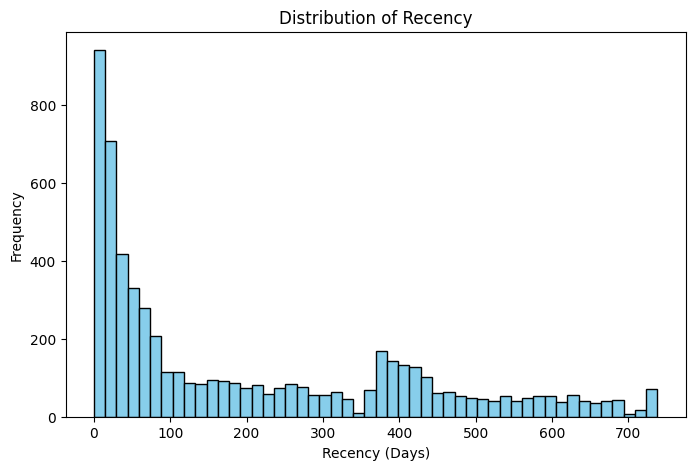

In [99]:
plt.figure(figsize=(8, 5))
plt.hist(rfm['RecencyDays'], bins=50, color='skyblue', edgecolor='black')
plt.xlabel('Recency (Days)')
plt.ylabel('Frequency')
plt.title('Distribution of Recency')
plt.show()

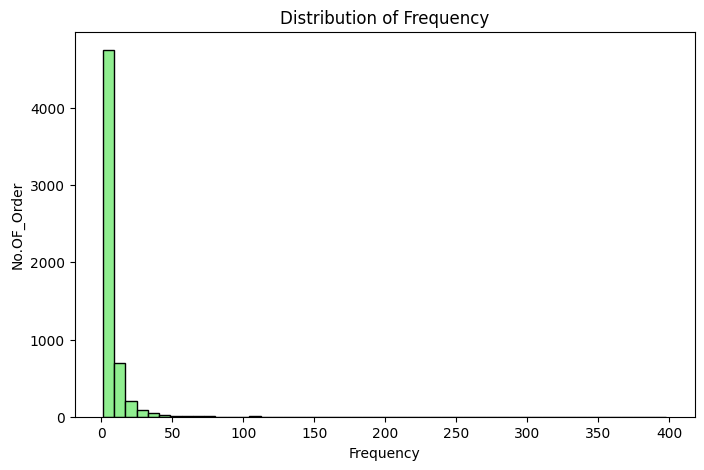

In [100]:
plt.figure(figsize=(8, 5))
plt.hist(rfm['Frequency'], bins=50, color='lightgreen', edgecolor='black')  
plt.xlabel('Frequency')
plt.ylabel('No.OF_Order')
plt.title('Distribution of Frequency')
plt.show()

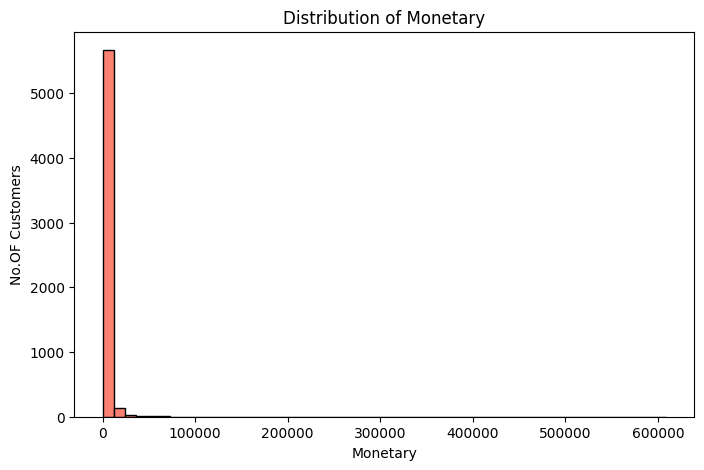

In [101]:
plt.figure(figsize=(8, 5))
plt.hist(rfm['Monetary'], bins=50, color='salmon', edgecolor='black')
plt.xlabel('Monetary')
plt.ylabel('No.OF Customers')
plt.title('Distribution of Monetary')
plt.show()

In [102]:
rfm[['RecencyDays', 'Frequency', 'Monetary']].quantile(
    [0, .25, .50, .75, .90, .95, .99, 1]
)

,RecencyDays,Frequency,Monetary
0.00,0.0,1.0,2.9500
0.25,25.0,1.0,348.7625
0.50,95.0,3.0,898.9150
0.75,379.0,7.0,2307.0900
0.90,534.0,13.0,5595.3650
0.95,624.0,21.0,9535.3360
0.99,725.0,46.0,29730.4202
1.00,738.0,398.0,608821.6500


In [103]:
import numpy as np

rfm['Recency_log'] = np.log1p(rfm['RecencyDays'])
rfm['Frequency_log'] = np.log1p(rfm['Frequency'])
rfm['Monetary_log'] = np.log1p(rfm['Monetary'])

In [104]:
rfm[
    [
        'RecencyDays',
        'Recency_log',
        'Frequency',
        'Frequency_log',
        'Monetary',
        'Monetary_log'
    ]
].head(10)

,RecencyDays,Recency_log,Frequency,Frequency_log,Monetary,Monetary_log
0,325,5.786897,12,2.564949,77556.46,11.258774
1,1,0.693147,8,2.197225,5633.32,8.636632
2,74,4.317488,5,1.791759,2019.40,7.611051
3,18,2.944439,4,1.609438,4428.69,8.396085
4,309,5.736572,1,0.693147,334.40,5.815324
5,374,5.926926,1,0.693147,300.93,5.710195
6,35,3.583519,10,2.397895,2849.84,7.955369
7,203,5.318120,2,1.098612,406.76,6.010679
8,231,5.446737,1,0.693147,1079.40,6.985087
9,213,5.365976,2,1.098612,947.61,6.854998


In [105]:
from sklearn.preprocessing import StandardScaler

In [106]:
rfm_features = rfm[
    [
        'Recency_log',
        'Frequency_log',
        'Monetary_log'
    ]
].copy()

In [107]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)


In [108]:
rfm_scaled

array([[ 0.8434165 ,  1.25449595,  3.18662493],
       [-2.26985977,  0.80016603,  1.2971269 ],
       [-0.05467956,  0.29920733,  0.55810028],
       ...,
       [ 1.27544386, -1.05814595, -0.56020813],
       [ 1.07604912, -0.55718724,  0.23894227],
       [-0.39468018,  0.65464319,  1.08267036]], shape=(5878, 3))

In [109]:
rfm_scaled=pd.DataFrame(
    rfm_scaled,
    columns=['Recency_log', 'Frequency_log', 'Monetary_log']
)

In [110]:
rfm_scaled

,Recency_log,Frequency_log,Monetary_log
0,0.843417,1.254496,3.186625
1,-2.269860,0.800166,1.297127
2,-0.054680,0.299207,0.558100
3,-0.893881,0.073946,1.123790
4,0.812658,-1.058146,-0.735888
...,...,...,...
5873,-1.846211,1.959413,0.777020
5874,1.015485,-1.058146,-0.504065
5875,1.275444,-1.058146,-0.560208
5876,1.076049,-0.557187,0.238942


In [111]:
rfm_scaled.describe()

,Recency_log,Frequency_log,Monetary_log
count,5.878000e+03,5.878000e+03,5.878000e+03
mean,7.494666e-17,2.381370e-16,-4.351742e-16
std,1.000085e+00,1.000085e+00,1.000085e+00
min,-2.693508e+00,-1.058146e+00,-3.936481e+00
25%,-7.021747e-01,-1.058146e+00,-7.056734e-01
50%,9.620016e-02,-2.017514e-01,-2.467978e-02
75%,9.370968e-01,6.546432e-01,6.540289e-01
max,1.343619e+00,5.484918e+00,4.671413e+00


In [112]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia.append(kmeans.inertia_)

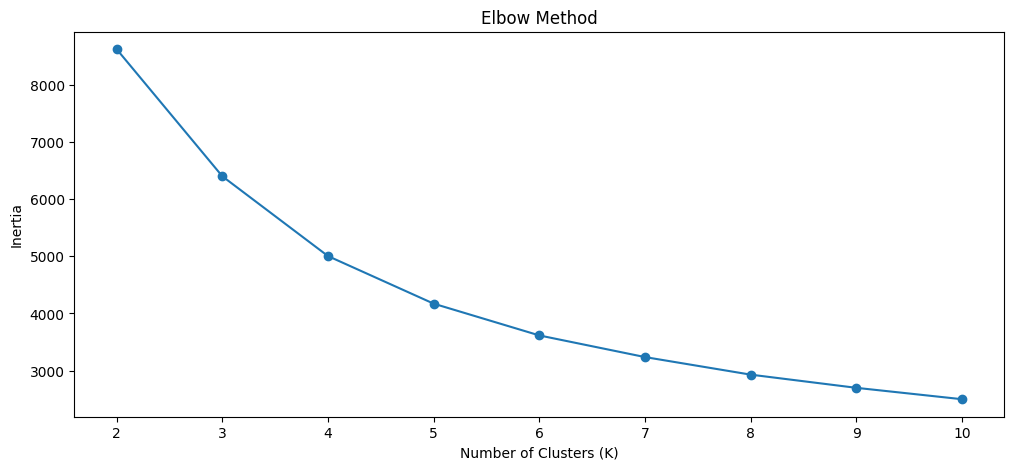

In [113]:
plt.figure(figsize=(12,5))

plt.plot(
    range(2, 11),
    inertia,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')

plt.show()

In [114]:
from sklearn.metrics import silhouette_score

In [115]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_scores.append(score)

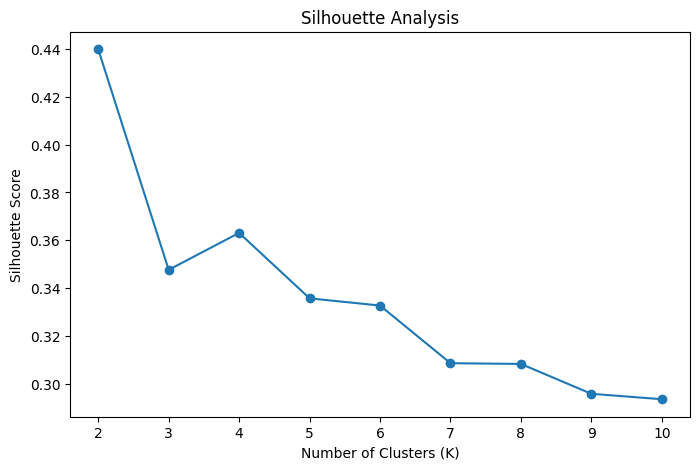

In [116]:
plt.figure(figsize=(8,5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')

plt.show()

In [117]:
rfm[['RecencyDays', 'Frequency', 'Monetary']].skew()

RecencyDays     0.887198
Frequency      12.639951
Monetary       25.314235
dtype: float64

In [118]:
rfm[['RecencyDays', 'Frequency', 'Monetary']].quantile(
    [0, .25, .50, .75, .90, .95, .99, 1]
)

,RecencyDays,Frequency,Monetary
0.00,0.0,1.0,2.9500
0.25,25.0,1.0,348.7625
0.50,95.0,3.0,898.9150
0.75,379.0,7.0,2307.0900
0.90,534.0,13.0,5595.3650
0.95,624.0,21.0,9535.3360
0.99,725.0,46.0,29730.4202
1.00,738.0,398.0,608821.6500


In [119]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_results = []

for k in [2, 3, 4, 5]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    cluster_results.append({
        'K': k,
        'Inertia': kmeans.inertia_,
        'Silhouette': score
    })

cluster_results = pd.DataFrame(cluster_results)

cluster_results

,K,Inertia,Silhouette
0,2,8619.324821,0.439879
1,3,6397.957258,0.347625
2,4,5003.120020,0.363068
3,5,4171.429839,0.335699


In [120]:
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans_4.fit_predict(rfm_scaled)

In [121]:
rfm['Cluster'].value_counts().sort_index()

Cluster
0    2061
1    1115
2    1212
3    1490
Name: count, dtype: int64

In [122]:
cluster_summary = (
    rfm
    .groupby('Cluster').agg({
        'RecencyDays': 'mean',
        'Frequency': 'mean',
        'Monetary': 'mean',
        'CustomerID': 'count'
    })
    .rename(columns={
        'CustomerID': 'CustomerCount'
    })
)

cluster_summary

,RecencyDays,Frequency,Monetary,CustomerCount
Cluster,,,,
0,390.379427,1.412906,343.840622,2061
1,24.308520,20.024215,11482.284993,1115
2,26.490099,3.039604,861.833327,1212
3,210.583221,5.400000,2139.250938,1490


In [123]:
rfm

,CustomerID,Monetary,Frequency,RecencyDays,Recency_log,Frequency_log,Monetary_log,Cluster
0,12346.0,77556.46,12,325,5.786897,2.564949,11.258774,1
1,12347.0,5633.32,8,1,0.693147,2.197225,8.636632,1
2,12348.0,2019.40,5,74,4.317488,1.791759,7.611051,3
3,12349.0,4428.69,4,18,2.944439,1.609438,8.396085,2
4,12350.0,334.40,1,309,5.736572,0.693147,5.815324,0
...,...,...,...,...,...,...,...,...
5873,18283.0,2736.65,22,3,1.386294,3.135494,7.914855,1
5874,18284.0,461.68,1,431,6.068426,0.693147,6.137036,0
5875,18285.0,427.00,1,660,6.493754,0.693147,6.059123,0
5876,18286.0,1296.43,2,476,6.167516,1.098612,7.168141,3


In [124]:
customer_df = customer_df.merge(
    rfm[['CustomerID', 'Cluster']],
    on='CustomerID',
    how='left'
)

In [125]:
customer_df.head(5)

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency,Country,TotalReturnedQuantity,ReturnOrders,ReturnOrderRate,Cluster
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,725,325,0.496552,United Kingdom,74233.0,5.0,0.416667,1
1,12347.0,5633.32,8,3286,126,2010-10-31 14:20:00,2011-12-07 15:52:00,704.165000,403,1,0.595533,Iceland,0.0,0.0,0.000000,1
2,12348.0,2019.40,5,2714,25,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,437,74,0.343249,Finland,0.0,0.0,0.000000,3
3,12349.0,4428.69,4,1624,138,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,588,18,0.204082,Italy,5.0,1.0,0.250000,2
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,309,309,0.097087,Norway,0.0,0.0,0.000000,0


In [126]:
cluster_profile = (
    customer_df
    .groupby('Cluster').agg(
        Customers=('CustomerID', 'count'),
        AvgRecency=('RecencyDays', 'mean'),
        AvgOrders=('TotalOrders', 'mean'),
        AvgRevenue=('TotalRevenue', 'mean'),
        AvgAOV=('AverageOrderValue', 'mean'),
        AvgReturnRate=('ReturnOrderRate', 'mean')
    )
    .round(2)
)

cluster_profile

,Customers,AvgRecency,AvgOrders,AvgRevenue,AvgAOV,AvgReturnRate
Cluster,,,,,,
0,2061,390.38,1.41,343.84,262.91,0.17
1,1115,24.31,20.02,11482.28,582.91,0.23
2,1212,26.49,3.04,861.83,319.75,0.15
3,1490,210.58,5.40,2139.25,485.38,0.24


In [127]:
rfm['Cluster'] = kmeans_4.fit_predict(rfm_scaled)

In [128]:
rfm['Cluster'].value_counts().sort_index()

Cluster
0    2061
1    1115
2    1212
3    1490
Name: count, dtype: int64

In [129]:
cluster_profile = (
    customer_df
    .groupby('Cluster')
    .agg(
        Customers=('CustomerID', 'count'),
        AvgRecency=('RecencyDays', 'mean'),
        AvgOrders=('TotalOrders', 'mean'),
        AvgRevenue=('TotalRevenue', 'mean'),
        AvgAOV=('AverageOrderValue', 'mean'),
        AvgReturnRate=('ReturnOrderRate', 'mean')
    )
    .round(2)
)

cluster_profile

,Customers,AvgRecency,AvgOrders,AvgRevenue,AvgAOV,AvgReturnRate
Cluster,,,,,,
0,2061,390.38,1.41,343.84,262.91,0.17
1,1115,24.31,20.02,11482.28,582.91,0.23
2,1212,26.49,3.04,861.83,319.75,0.15
3,1490,210.58,5.40,2139.25,485.38,0.24


In [130]:
segment_names = {
    0: 'Dormant / Lost',
    1: 'VIP / High-Value Loyal',
    2: 'Active Potential',
    3: 'At-Risk'
}

customer_df['CustomerSegment'] = (
    customer_df['Cluster'].map(segment_names)
)

In [131]:
customer_df.head(5)

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,customerTenureDays,RecencyDays,PurchaseFrequency,Country,TotalReturnedQuantity,ReturnOrders,ReturnOrderRate,Cluster,CustomerSegment
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,725,325,0.496552,United Kingdom,74233.0,5.0,0.416667,1,VIP / High-Value Loyal
1,12347.0,5633.32,8,3286,126,2010-10-31 14:20:00,2011-12-07 15:52:00,704.165000,403,1,0.595533,Iceland,0.0,0.0,0.000000,1,VIP / High-Value Loyal
2,12348.0,2019.40,5,2714,25,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,437,74,0.343249,Finland,0.0,0.0,0.000000,3,At-Risk
3,12349.0,4428.69,4,1624,138,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,588,18,0.204082,Italy,5.0,1.0,0.250000,2,Active Potential
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,309,309,0.097087,Norway,0.0,0.0,0.000000,0,Dormant / Lost


In [132]:
rfm = rfm.merge(customer_df[['CustomerID', 'CustomerSegment']], on='CustomerID', how='left')

In [133]:
customer_df[
    [
        'CustomerID',
        'RecencyDays',
        'TotalOrders',
        'TotalRevenue',
        'Cluster',
        'CustomerSegment'
    ]
].head(10)

,CustomerID,RecencyDays,TotalOrders,TotalRevenue,Cluster,CustomerSegment
0,12346.0,325,12,77556.46,1,VIP / High-Value Loyal
1,12347.0,1,8,5633.32,1,VIP / High-Value Loyal
2,12348.0,74,5,2019.40,3,At-Risk
3,12349.0,18,4,4428.69,2,Active Potential
4,12350.0,309,1,334.40,0,Dormant / Lost
5,12351.0,374,1,300.93,0,Dormant / Lost
6,12352.0,35,10,2849.84,1,VIP / High-Value Loyal
7,12353.0,203,2,406.76,0,Dormant / Lost
8,12354.0,231,1,1079.40,0,Dormant / Lost
9,12355.0,213,2,947.61,3,At-Risk


In [134]:
segment_summary = (
    customer_df
    .groupby('CustomerSegment')
    .agg(
        Customers=('CustomerID', 'count'),
        AvgRecency=('RecencyDays', 'mean'),
        AvgOrders=('TotalOrders', 'mean'),
        AvgRevenue=('TotalRevenue', 'mean'),
        TotalRevenue=('TotalRevenue', 'sum')
    )
    .round(2)
)

segment_summary

,Customers,AvgRecency,AvgOrders,AvgRevenue,TotalRevenue
CustomerSegment,,,,,
Active Potential,1212,26.49,3.04,861.83,1044541.99
At-Risk,1490,210.58,5.40,2139.25,3187483.90
Dormant / Lost,2061,390.38,1.41,343.84,708655.52
VIP / High-Value Loyal,1115,24.31,20.02,11482.28,12802747.77


In [135]:
segment_summary['RevenueContributionPercent'] = (
    segment_summary['TotalRevenue'] /
    segment_summary['TotalRevenue'].sum() * 100
).round(2)

segment_summary.sort_values(
    'RevenueContributionPercent',
    ascending=False
)

,Customers,AvgRecency,AvgOrders,AvgRevenue,TotalRevenue,RevenueContributionPercent
CustomerSegment,,,,,,
VIP / High-Value Loyal,1115,24.31,20.02,11482.28,12802747.77,72.15
At-Risk,1490,210.58,5.40,2139.25,3187483.90,17.96
Active Potential,1212,26.49,3.04,861.83,1044541.99,5.89
Dormant / Lost,2061,390.38,1.41,343.84,708655.52,3.99


In [136]:
AvgReturnOrderRate=('ReturnOrderRate', 'mean')

In [137]:
cluster_profile=cluster_profile.rename(columns={'AvgReturnRate':'AvgReturnOrderRate'})

In [138]:
cluster_profile 

,Customers,AvgRecency,AvgOrders,AvgRevenue,AvgAOV,AvgReturnOrderRate
Cluster,,,,,,
0,2061,390.38,1.41,343.84,262.91,0.17
1,1115,24.31,20.02,11482.28,582.91,0.23
2,1212,26.49,3.04,861.83,319.75,0.15
3,1490,210.58,5.40,2139.25,485.38,0.24


In [139]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

In [140]:
rfm_scaled

,Recency_log,Frequency_log,Monetary_log
0,0.843417,1.254496,3.186625
1,-2.269860,0.800166,1.297127
2,-0.054680,0.299207,0.558100
3,-0.893881,0.073946,1.123790
4,0.812658,-1.058146,-0.735888
...,...,...,...
5873,-1.846211,1.959413,0.777020
5874,1.015485,-1.058146,-0.504065
5875,1.275444,-1.058146,-0.560208
5876,1.076049,-0.557187,0.238942


In [141]:
linked = linkage(
    rfm_scaled,
    method='ward'
)

In [142]:
linked

array([[4.25000000e+02, 5.59100000e+03, 0.00000000e+00, 2.00000000e+00],
       [5.50900000e+03, 5.52000000e+03, 8.42158778e-05, 2.00000000e+00],
       [3.73700000e+03, 4.50700000e+03, 8.78815524e-05, 2.00000000e+00],
       ...,
       [1.17410000e+04, 1.17490000e+04, 4.99375648e+01, 2.24600000e+03],
       [1.17500000e+04, 1.17520000e+04, 6.80374794e+01, 4.31900000e+03],
       [1.17510000e+04, 1.17530000e+04, 1.28833160e+02, 5.87800000e+03]],
      shape=(5877, 4))

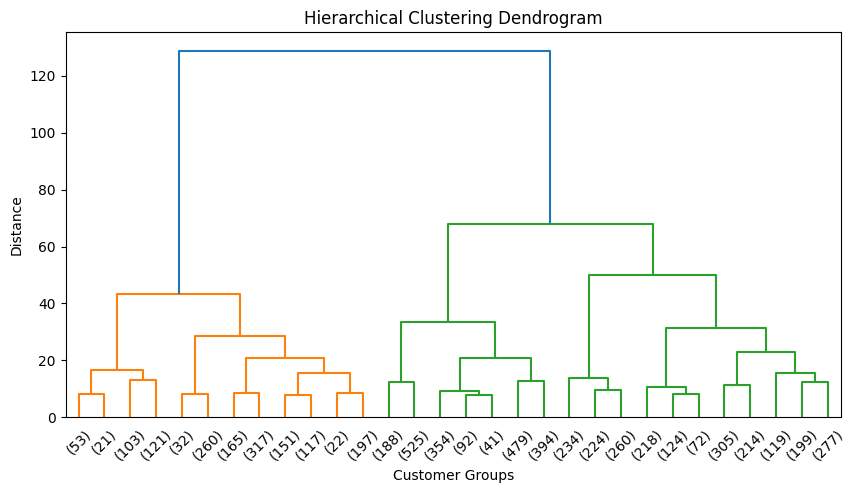

In [143]:
plt.figure(figsize=(10, 5))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customer Groups')
plt.ylabel('Distance')

plt.show()

In [144]:
hierarchical_4 = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hierarchical_labels = hierarchical_4.fit_predict(
    rfm_scaled
)

In [145]:
rfm['HierarchicalCluster'] = hierarchical_labels

In [146]:
rfm['HierarchicalCluster'].value_counts().sort_index()

HierarchicalCluster
0    1559
1    1528
2    2073
3     718
Name: count, dtype: int64

In [147]:
rfm

,CustomerID,Monetary,Frequency,RecencyDays,Recency_log,Frequency_log,Monetary_log,Cluster,CustomerSegment,HierarchicalCluster
0,12346.0,77556.46,12,325,5.786897,2.564949,11.258774,1,VIP / High-Value Loyal,0
1,12347.0,5633.32,8,1,0.693147,2.197225,8.636632,1,VIP / High-Value Loyal,0
2,12348.0,2019.40,5,74,4.317488,1.791759,7.611051,3,At-Risk,3
3,12349.0,4428.69,4,18,2.944439,1.609438,8.396085,2,Active Potential,0
4,12350.0,334.40,1,309,5.736572,0.693147,5.815324,0,Dormant / Lost,2
...,...,...,...,...,...,...,...,...,...,...
5873,18283.0,2736.65,22,3,1.386294,3.135494,7.914855,1,VIP / High-Value Loyal,0
5874,18284.0,461.68,1,431,6.068426,0.693147,6.137036,0,Dormant / Lost,2
5875,18285.0,427.00,1,660,6.493754,0.693147,6.059123,0,Dormant / Lost,2
5876,18286.0,1296.43,2,476,6.167516,1.098612,7.168141,3,At-Risk,2


In [148]:
hierarchical_profile = (
    rfm
    .groupby('HierarchicalCluster').agg(
        Customers=('CustomerID', 'count'),
        AvgRecency=('RecencyDays', 'mean'),
        AvgFrequency=('Frequency', 'mean'),
        AvgMonetary=('Monetary', 'mean')
    )
    .round(2)
)

hierarchical_profile

,Customers,AvgRecency,AvgFrequency,AvgMonetary
HierarchicalCluster,,,,
0,1559,39.44,16.48,9121.76
1,1528,40.82,2.77,751.13
2,2073,414.99,1.56,521.50
3,718,269.39,5.30,1801.96


In [149]:
hierarchical_silhouette = silhouette_score(
    rfm_scaled,
    hierarchical_labels
)

hierarchical_silhouette

0.2932495065988767

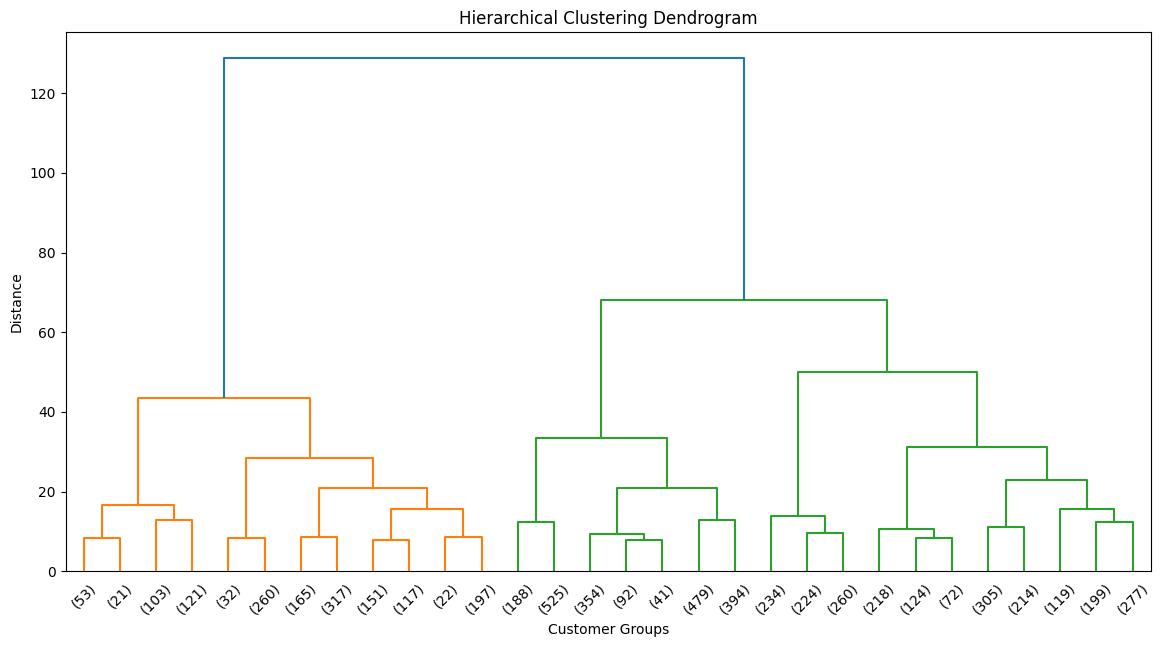

In [150]:
linked = linkage(rfm_scaled, method='ward')

plt.figure(figsize=(14, 7))
dendrogram(linked, truncate_mode='lastp', p=30)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customer Groups')
plt.ylabel('Distance')
plt.show()

In [151]:
hierarchical_4 = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward'
)

hierarchical_labels = hierarchical_4.fit_predict(rfm_scaled)

In [152]:
hierarchical_labels

array([0, 0, 3, ..., 2, 2, 0], shape=(5878,))

In [153]:
rfm['HierarchicalCluster'] = hierarchical_labels

rfm['HierarchicalCluster'].value_counts().sort_index()

HierarchicalCluster
0    1559
1    1528
2    2073
3     718
Name: count, dtype: int64

In [154]:
hierarchical_profile = (
    rfm
    .groupby('HierarchicalCluster')
    .agg(
        Customers=('CustomerID', 'count'),
        AvgRecency=('RecencyDays', 'mean'),
        AvgFrequency=('Frequency', 'mean'),
        AvgMonetary=('Monetary', 'mean')
    )
    .round(2)
)

print(hierarchical_profile)

print(
    "Hierarchical Silhouette:",
    silhouette_score(rfm_scaled, hierarchical_labels)
)

                     Customers  AvgRecency  AvgFrequency  AvgMonetary
HierarchicalCluster                                                  
0                         1559       39.44         16.48      9121.76
1                         1528       40.82          2.77       751.13
2                         2073      414.99          1.56       521.50
3                          718      269.39          5.30      1801.96
Hierarchical Silhouette: 0.2932495065988767


In [155]:
comparison = pd.DataFrame({
    'Algorithm': [
        'K-Means',
        'Hierarchical'
    ],
    'Clusters': [
        4,
        4
    ],
    'Silhouette': [
        silhouette_score(rfm_scaled, rfm['Cluster']),
        silhouette_score(rfm_scaled, rfm['HierarchicalCluster'])
    ]
})

comparison

,Algorithm,Clusters,Silhouette
0,K-Means,4,0.363068
1,Hierarchical,4,0.293250


In [156]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    rfm['Cluster'],
    rfm['HierarchicalCluster']
)

print("Adjusted Rand Index:", ari)

Adjusted Rand Index: 0.5859950458644753


In [157]:
from sklearn.neighbors import NearestNeighbors

In [158]:
min_samples = 5
neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors_fit = neighbors.fit(rfm_scaled)

distances, indices = neighbors_fit.kneighbors(
    rfm_scaled
)

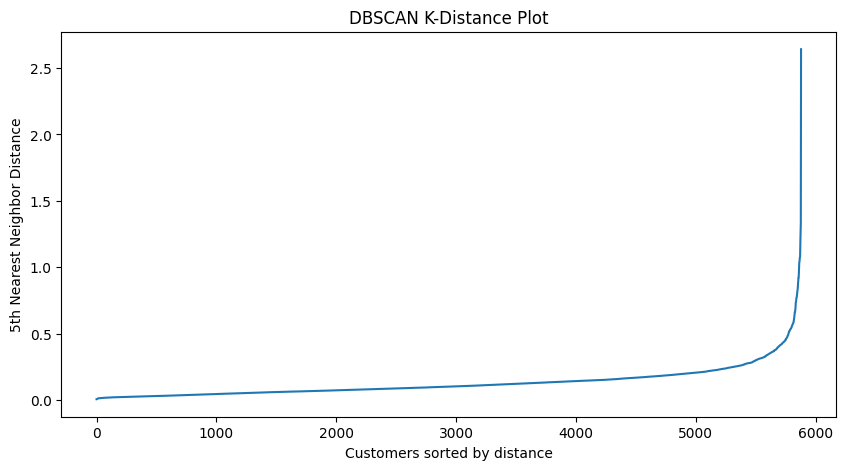

In [159]:
distances = np.sort(
    distances[:, min_samples - 1]
)
plt.figure(figsize=(10, 5))

plt.plot(distances)

plt.xlabel('Customers sorted by distance')
plt.ylabel('5th Nearest Neighbor Distance')
plt.title('DBSCAN K-Distance Plot')

plt.show()

In [160]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

In [161]:
eps_values = [0.35, 0.40, 0.45, 0.50, 0.55]

dbscan_results = []

for eps in eps_values:

    dbscan = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = dbscan.fit_predict(rfm_scaled)

    # -1 means noise/outlier
    n_noise = np.sum(labels == -1)

    n_clusters = len(
        set(labels) - {-1}
    )

    noise_percent = (
        n_noise / len(labels) * 100
    )

    # Silhouette should be calculated on non-noise points
    mask = labels != -1

    if n_clusters >= 2 and mask.sum() > n_clusters:
        silhouette = silhouette_score(
            rfm_scaled[mask],
            labels[mask]
        )
    else:
        silhouette = np.nan

    dbscan_results.append({
        'EPS': eps,
        'Clusters': n_clusters,
        'NoiseCustomers': n_noise,
        'NoisePercent': round(noise_percent, 2),
        'Silhouette': silhouette
    })

dbscan_results = pd.DataFrame(dbscan_results)

dbscan_results

,EPS,Clusters,NoiseCustomers,NoisePercent,Silhouette
0,0.35,4,159,2.71,0.108172
1,0.40,4,114,1.94,0.160738
2,0.45,2,75,1.28,0.278112
3,0.50,2,64,1.09,0.277316
4,0.55,1,47,0.80,NaN


In [162]:
eps_values_fine = [
    0.36, 0.37, 0.38, 0.39, 0.40,
    0.41, 0.42, 0.43, 0.44, 0.45
]

dbscan_fine_results = []

for eps in eps_values_fine:

    dbscan = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = dbscan.fit_predict(rfm_scaled)

    n_noise = np.sum(labels == -1)

    n_clusters = len(set(labels) - {-1})

    noise_percent = (
        n_noise / len(labels) * 100
    )

    mask = labels != -1

    if n_clusters >= 2 and mask.sum() > n_clusters:

        silhouette = silhouette_score(
            rfm_scaled[mask],
            labels[mask]
        )

    else:
        silhouette = np.nan

    dbscan_fine_results.append({
        'EPS': eps,
        'Clusters': n_clusters,
        'NoiseCustomers': n_noise,
        'NoisePercent': round(noise_percent, 2),
        'Silhouette': round(silhouette, 4)
        if not np.isnan(silhouette)
        else np.nan
    })

dbscan_fine_results = pd.DataFrame(
    dbscan_fine_results
)

dbscan_fine_results

,EPS,Clusters,NoiseCustomers,NoisePercent,Silhouette
0,0.36,3,146,2.48,0.2013
1,0.37,3,134,2.28,0.1998
2,0.38,4,124,2.11,0.1613
3,0.39,4,121,2.06,0.1616
4,0.40,4,114,1.94,0.1607
5,0.41,4,108,1.84,0.1602
6,0.42,3,98,1.67,0.1986
7,0.43,2,89,1.51,0.2794
8,0.44,2,78,1.33,0.2783
9,0.45,2,75,1.28,0.2781


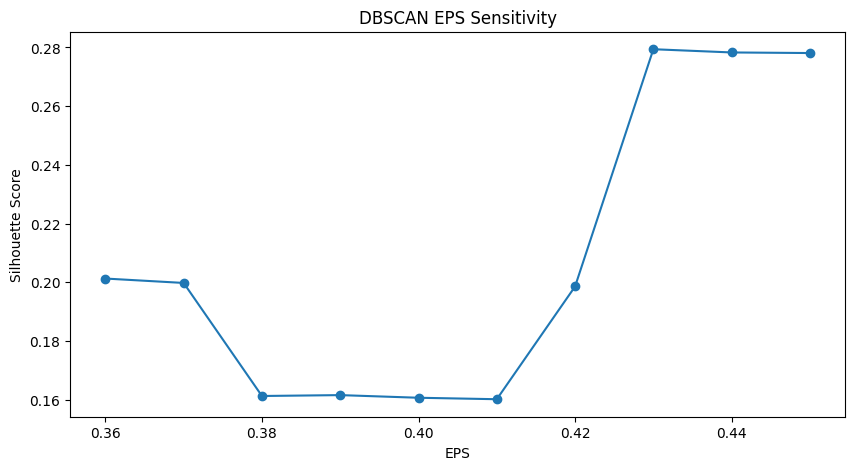

In [163]:
plt.figure(figsize=(10, 5))

plt.plot(
    dbscan_fine_results['EPS'],
    dbscan_fine_results['Silhouette'],
    marker='o'
)

plt.xlabel('EPS')
plt.ylabel('Silhouette Score')
plt.title('DBSCAN EPS Sensitivity')

plt.show()

In [164]:
from sklearn.cluster import DBSCAN

dbscan_final = DBSCAN(
    eps=0.40,
    min_samples=5
)

dbscan_labels = dbscan_final.fit_predict(rfm_scaled)

rfm['DBSCANCluster'] = dbscan_labels

In [165]:
rfm['DBSCANCluster'].value_counts().sort_index()

DBSCANCluster
-1     114
 0    4086
 1    1603
 2      71
 3       4
Name: count, dtype: int64

In [166]:
dbscan_outliers = rfm[
    rfm['DBSCANCluster'] == -1
].copy()

dbscan_outliers.head()

,CustomerID,Monetary,Frequency,RecencyDays,Recency_log,Frequency_log,Monetary_log,Cluster,CustomerSegment,HierarchicalCluster,DBSCANCluster
0,12346.0,77556.46,12,325,5.786897,2.564949,11.258774,1,VIP / High-Value Loyal,0,-1
11,12357.0,18287.66,3,32,3.496508,1.386294,9.814036,1,VIP / High-Value Loyal,0,-1
32,12378.0,5416.32,2,129,4.867534,1.098612,8.597357,3,At-Risk,2,-1
62,12409.0,23419.29,7,78,4.369448,2.079442,10.061358,1,VIP / High-Value Loyal,0,-1
68,12415.0,144458.37,28,23,3.178054,3.367296,11.880754,1,VIP / High-Value Loyal,0,-1


In [167]:
dbscan_outliers[
    [
        'CustomerID',
        'RecencyDays',
        'Frequency',
        'Monetary'
    ]
].sort_values(
    'Monetary',
    ascending=False
).head(20)

,CustomerID,RecencyDays,Frequency,Monetary
5692,18102.0,0,145,608821.65
2277,14646.0,1,151,528602.52
1789,14156.0,9,156,313946.37
2538,14911.0,0,398,295972.63
5050,17450.0,7,51,246973.09
1331,13694.0,3,143,196482.81
5109,17511.0,2,60,175603.55
4061,16446.0,0,2,168472.50
4295,16684.0,3,55,147142.77
68,12415.0,23,28,144458.37


In [168]:
dbscan_outliers[
    [
        'CustomerID',
        'RecencyDays',
        'Frequency',
        'Monetary'
    ]
].sort_values(
    'Monetary',
    ascending=True
).head(20)

,CustomerID,RecencyDays,Frequency,Monetary
1730,14095.0,722,1,2.95
1424,13788.0,504,1,3.75
4348,16738.0,297,1,3.75
2421,14792.0,63,1,6.20
4487,16878.0,83,1,13.30
3711,16093.0,106,1,17.00
5577,17986.0,55,1,20.80
2241,14610.0,395,2,24.35
4069,16454.0,44,4,30.95
5774,18184.0,14,1,49.80


In [169]:
rfm[['CustomerID', 'Cluster', 'DBSCANCluster']].head()

,CustomerID,Cluster,DBSCANCluster
0,12346.0,1,-1
1,12347.0,1,0
2,12348.0,3,0
3,12349.0,2,0
4,12350.0,0,1


In [170]:
outlier_segment_analysis = pd.crosstab(
    rfm['Cluster'],
    rfm['DBSCANCluster']
)

outlier_segment_analysis

DBSCANCluster,-1,0,1,2,3
Cluster,,,,,
0,12,671,1375,0,3
1,68,994,0,53,0
2,16,963,214,18,1
3,18,1458,14,0,0


In [171]:
dbscan_final = DBSCAN(
    eps=0.40,
    min_samples=5
)

dbscan_labels = dbscan_final.fit_predict(rfm_scaled)

rfm['DBSCANCluster'] = dbscan_labels

In [172]:
dbscan_labels

array([-1,  0,  0, ...,  1,  0,  0], shape=(5878,))

In [173]:
dbscan_outliers = rfm[
    rfm['DBSCANCluster'] == -1
].copy()

dbscan_outliers[
    ['CustomerID', 'RecencyDays', 'Frequency', 'Monetary']
].sort_values(
    'Monetary',
    ascending=False
).head(20)

,CustomerID,RecencyDays,Frequency,Monetary
5692,18102.0,0,145,608821.65
2277,14646.0,1,151,528602.52
1789,14156.0,9,156,313946.37
2538,14911.0,0,398,295972.63
5050,17450.0,7,51,246973.09
1331,13694.0,3,143,196482.81
5109,17511.0,2,60,175603.55
4061,16446.0,0,2,168472.50
4295,16684.0,3,55,147142.77
68,12415.0,23,28,144458.37


In [174]:
pd.crosstab(
    rfm['Cluster'],
    rfm['DBSCANCluster']
)

DBSCANCluster,-1,0,1,2,3
Cluster,,,,,
0,12,671,1375,0,3
1,68,994,0,53,0
2,16,963,214,18,1
3,18,1458,14,0,0


In [175]:
rfm['BehavioralOutlier'] = (
    rfm['DBSCANCluster'] == -1
).astype(int)

In [176]:
rfm['BehavioralOutlier'].value_counts()

BehavioralOutlier
0    5764
1     114
Name: count, dtype: int64

In [177]:
rfm.columns

Index(['CustomerID', 'Monetary', 'Frequency', 'RecencyDays', 'Recency_log',
       'Frequency_log', 'Monetary_log', 'Cluster', 'CustomerSegment',
       'HierarchicalCluster', 'DBSCANCluster', 'BehavioralOutlier'],
      dtype='object')

In [178]:
outlier_by_segment = (
    rfm.groupby('CustomerSegment').agg(
        Customers=('CustomerID', 'count'),
        Outliers=('BehavioralOutlier', 'sum')
    )
)

outlier_by_segment['OutlierRate'] = (
    outlier_by_segment['Outliers'] /
    outlier_by_segment['Customers'] * 100
).round(2)

outlier_by_segment.sort_values(
    'OutlierRate',
    ascending=False
)

,Customers,Outliers,OutlierRate
CustomerSegment,,,
VIP / High-Value Loyal,1115,68,6.10
Active Potential,1212,16,1.32
At-Risk,1490,18,1.21
Dormant / Lost,2061,12,0.58


In [179]:
print(rfm.columns)

Index(['CustomerID', 'Monetary', 'Frequency', 'RecencyDays', 'Recency_log',
       'Frequency_log', 'Monetary_log', 'Cluster', 'CustomerSegment',
       'HierarchicalCluster', 'DBSCANCluster', 'BehavioralOutlier'],
      dtype='object')


In [180]:
rfm.columns.tolist()

['CustomerID',
 'Monetary',
 'Frequency',
 'RecencyDays',
 'Recency_log',
 'Frequency_log',
 'Monetary_log',
 'Cluster',
 'CustomerSegment',
 'HierarchicalCluster',
 'DBSCANCluster',
 'BehavioralOutlier']

In [181]:
rfm.drop(columns=['CustomerSegment_y'], inplace=True, errors='ignore')

In [182]:
rfm=rfm.rename(columns={'CustomerSegment_x':'CustomerSegment'})

In [183]:
rfm.columns.tolist()

['CustomerID',
 'Monetary',
 'Frequency',
 'RecencyDays',
 'Recency_log',
 'Frequency_log',
 'Monetary_log',
 'Cluster',
 'CustomerSegment',
 'HierarchicalCluster',
 'DBSCANCluster',
 'BehavioralOutlier']

In [184]:
outlier_by_segment = (
    rfm.groupby('CustomerSegment').agg(
        Customers=('CustomerID', 'count'),
        Outliers=('BehavioralOutlier', 'sum')
    )
)

outlier_by_segment['OutlierRate'] = (
    outlier_by_segment['Outliers'] /
    outlier_by_segment['Customers'] * 100
).round(2)

outlier_by_segment.sort_values(
    'OutlierRate',
    ascending=False
)

,Customers,Outliers,OutlierRate
CustomerSegment,,,
VIP / High-Value Loyal,1115,68,6.10
Active Potential,1212,16,1.32
At-Risk,1490,18,1.21
Dormant / Lost,2061,12,0.58


In [185]:
outlier_revenue = (
    rfm
    .groupby('BehavioralOutlier')
    .agg(
        Customers=('CustomerID', 'count'),
        TotalRevenue=('Monetary', 'sum'),
        AvgRevenue=('Monetary', 'mean')
    )
)

outlier_revenue

,Customers,TotalRevenue,AvgRevenue
BehavioralOutlier,,,
0,5764,1.201003e+07,2083.628153
1,114,5.733397e+06,50292.951781


In [186]:
outlier_revenue['RevenueContribution'] = (
    outlier_revenue['TotalRevenue'] /
    outlier_revenue['TotalRevenue'].sum() * 100
).round(2)

outlier_revenue

,Customers,TotalRevenue,AvgRevenue,RevenueContribution
BehavioralOutlier,,,,
0,5764,1.201003e+07,2083.628153,67.69
1,114,5.733397e+06,50292.951781,32.31


In [187]:
vip_outliers = rfm[
    (rfm['CustomerSegment'] == 'VIP / High-Value Loyal') &
    (rfm['BehavioralOutlier'] == 1)
].copy()

In [188]:
vip_outliers[
    [
        'CustomerID',
        'RecencyDays',
        'Frequency',
        'Monetary'
    ]
].sort_values(
    'Monetary',
    ascending=False
).head(20)

,CustomerID,RecencyDays,Frequency,Monetary
5692,18102.0,0,145,608821.65
2277,14646.0,1,151,528602.52
1789,14156.0,9,156,313946.37
2538,14911.0,0,398,295972.63
5050,17450.0,7,51,246973.09
1331,13694.0,3,143,196482.81
5109,17511.0,2,60,175603.55
4061,16446.0,0,2,168472.50
4295,16684.0,3,55,147142.77
68,12415.0,23,28,144458.37


In [189]:
rfm['BehavioralOutlier'] = (
    rfm['DBSCANCluster'] == -1
).astype(int)

In [190]:
outlier_revenue = (
    rfm
    .groupby('BehavioralOutlier')
    .agg(
        Customers=('CustomerID', 'count'),
        TotalRevenue=('Monetary', 'sum'),
        AvgRevenue=('Monetary', 'mean')
    )
)

outlier_revenue['RevenueContribution'] = (
    outlier_revenue['TotalRevenue'] /
    outlier_revenue['TotalRevenue'].sum() * 100
).round(2)

outlier_revenue

,Customers,TotalRevenue,AvgRevenue,RevenueContribution
BehavioralOutlier,,,,
0,5764,1.201003e+07,2083.628153,67.69
1,114,5.733397e+06,50292.951781,32.31


In [191]:
segment_outlier_revenue = (
    rfm
    .groupby(
        ['CustomerSegment', 'BehavioralOutlier']
    )
    .agg(
        Customers=('CustomerID', 'count'),
        TotalRevenue=('Monetary', 'sum'),
        AvgRevenue=('Monetary', 'mean')
    )
    .reset_index()
)

segment_outlier_revenue

,CustomerSegment,BehavioralOutlier,Customers,TotalRevenue,AvgRevenue
0,Active Potential,0,1196,1034359.362,864.848965
1,Active Potential,1,16,10182.630,636.414375
2,At-Risk,0,1472,2924541.868,1986.781160
3,At-Risk,1,18,262942.030,14607.890556
4,Dormant / Lost,0,2049,708202.541,345.633256
5,Dormant / Lost,1,12,452.980,37.748333
6,VIP / High-Value Loyal,0,1047,7342928.904,7013.303633
7,VIP / High-Value Loyal,1,68,5459818.863,80291.453868


In [192]:
segment_outlier_revenue.sort_values(
    'TotalRevenue',
    ascending=False
)

,CustomerSegment,BehavioralOutlier,Customers,TotalRevenue,AvgRevenue
6,VIP / High-Value Loyal,0,1047,7342928.904,7013.303633
7,VIP / High-Value Loyal,1,68,5459818.863,80291.453868
2,At-Risk,0,1472,2924541.868,1986.781160
0,Active Potential,0,1196,1034359.362,864.848965
4,Dormant / Lost,0,2049,708202.541,345.633256
3,At-Risk,1,18,262942.030,14607.890556
1,Active Potential,1,16,10182.630,636.414375
5,Dormant / Lost,1,12,452.980,37.748333


In [193]:
segment_revenue = (
    rfm
    .groupby('CustomerSegment')
    .agg(
        TotalRevenue=('Monetary', 'sum'),
        Customers=('CustomerID', 'count'),
        OutlierRevenue=(
            'Monetary',
            lambda x: x[
                rfm.loc[x.index, 'BehavioralOutlier'] == 1
            ].sum()
        ),
        OutlierCustomers=(
            'BehavioralOutlier',
            'sum'
        )
    )
)

segment_revenue['OutlierRevenuePercent'] = (
    segment_revenue['OutlierRevenue'] /
    segment_revenue['TotalRevenue'] * 100
).round(2)

segment_revenue

,TotalRevenue,Customers,OutlierRevenue,OutlierCustomers,OutlierRevenuePercent
CustomerSegment,,,,,
Active Potential,1.044542e+06,1212,10182.630,16,0.97
At-Risk,3.187484e+06,1490,262942.030,18,8.25
Dormant / Lost,7.086555e+05,2061,452.980,12,0.06
VIP / High-Value Loyal,1.280275e+07,1115,5459818.863,68,42.65


In [194]:
#==========================================================PCA BEGIN FROM HERE================================================

from sklearn.decomposition import PCA

In [195]:
from sklearn.decomposition import PCA

In [196]:
pca = PCA()

rfm_pca = pca.fit_transform(rfm_scaled)

In [197]:
pca.explained_variance_ratio_

array([0.7634543 , 0.18798187, 0.04856383])

In [198]:
import numpy as np

explained_variance = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance
)

for i, value in enumerate(cumulative_variance, 1):
    print(
        f"PC{i}: "
        f"{value*100:.2f}% cumulative variance"
    )

PC1: 76.35% cumulative variance
PC2: 95.14% cumulative variance
PC3: 100.00% cumulative variance


In [199]:
loadings = pd.DataFrame(
    pca.components_,
    columns=['RecencyDays', 'Frequency', 'Monetary'],
    index=['PC1', 'PC2', 'PC3']
)

loadings

,RecencyDays,Frequency,Monetary
PC1,-0.504085,0.617575,0.603738
PC2,0.860004,0.294734,0.416563
PC3,0.079317,0.729200,-0.679688


In [200]:
rfm_pca_2d = pd.DataFrame(
    rfm_pca[:, :2],
    columns=['PC1', 'PC2'],
    index=rfm.index
)

rfm_pca_2d['CustomerSegment'] = (
    rfm['CustomerSegment'].values
)

rfm_pca_2d['BehavioralOutlier'] = (
    rfm['BehavioralOutlier'].values
)

rfm_pca_2d.head()

,PC1,PC2,CustomerSegment,BehavioralOutlier
0,2.273477,2.422515,VIP / High-Value Loyal,1
1,2.421490,-1.175917,VIP / High-Value Loyal,0
2,0.549292,0.273646,At-Risk,0
3,1.174734,-0.278817,Active Potential,0
4,-1.507417,0.080474,Dormant / Lost,0


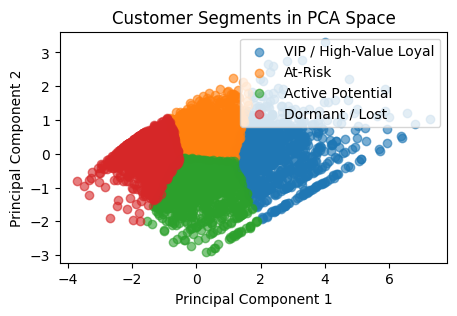

In [201]:
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 3))

for segment in rfm_pca_2d['CustomerSegment'].unique():

    subset = rfm_pca_2d[
        rfm_pca_2d['CustomerSegment'] == segment
    ]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=segment,
        alpha=0.6
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Customer Segments in PCA Space')
plt.legend()
plt.show()

In [202]:
rfm_pca_2d = pd.DataFrame(
    rfm_pca[:, :2],
    columns=['PC1', 'PC2'],
    index=rfm.index
)

rfm_pca_2d['CustomerSegment'] = (
    rfm['CustomerSegment'].values
)

rfm_pca_2d['BehavioralOutlier'] = (
    rfm['BehavioralOutlier'].values
)

rfm_pca_2d.head()

,PC1,PC2,CustomerSegment,BehavioralOutlier
0,2.273477,2.422515,VIP / High-Value Loyal,1
1,2.421490,-1.175917,VIP / High-Value Loyal,0
2,0.549292,0.273646,At-Risk,0
3,1.174734,-0.278817,Active Potential,0
4,-1.507417,0.080474,Dormant / Lost,0


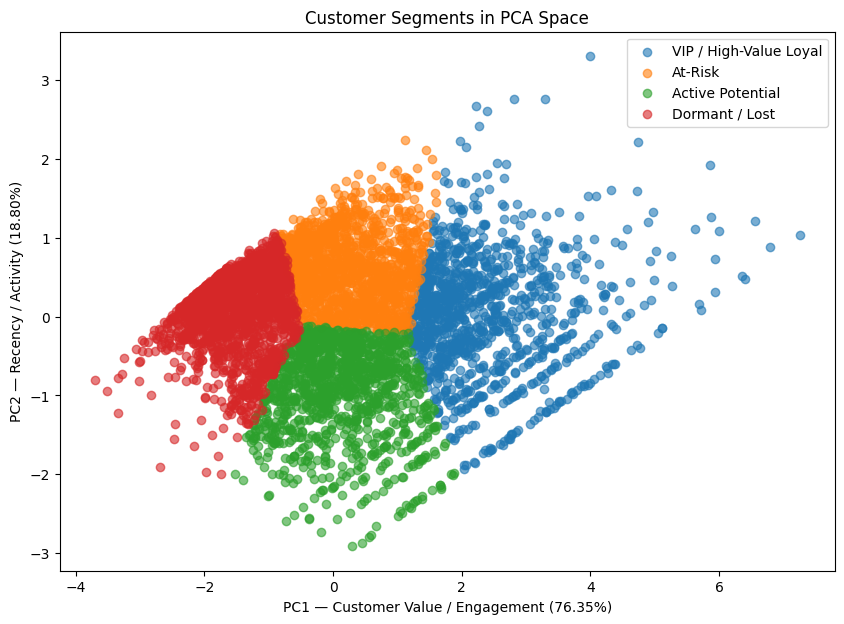

In [203]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for segment in rfm_pca_2d['CustomerSegment'].unique():

    subset = rfm_pca_2d[
        rfm_pca_2d['CustomerSegment'] == segment
    ]

    plt.scatter(
        subset['PC1'],
        subset['PC2'],
        label=segment,
        alpha=0.6
    )

plt.xlabel(
    'PC1 — Customer Value / Engagement (76.35%)'
)

plt.ylabel(
    'PC2 — Recency / Activity (18.80%)'
)

plt.title(
    'Customer Segments in PCA Space'
)

plt.legend()

plt.show()

In [204]:
customer_df.columns.tolist()

['CustomerID',
 'TotalRevenue',
 'TotalOrders',
 'TotalQuantity',
 'TotalProducts',
 'FirstPurchaseDate',
 'LastPurchaseDate',
 'AverageOrderValue',
 'customerTenureDays',
 'RecencyDays',
 'PurchaseFrequency',
 'Country',
 'TotalReturnedQuantity',
 'ReturnOrders',
 'ReturnOrderRate',
 'Cluster',
 'CustomerSegment']

In [205]:
customer_df[['CustomerID', 'FirstPurchaseDate', 'LastPurchaseDate']].head()

,CustomerID,FirstPurchaseDate,LastPurchaseDate
0,12346.0,2009-12-14 08:34:00,2011-01-18 10:01:00
1,12347.0,2010-10-31 14:20:00,2011-12-07 15:52:00
2,12348.0,2010-09-27 14:59:00,2011-09-25 13:13:00
3,12349.0,2010-04-29 13:20:00,2011-11-21 09:51:00
4,12350.0,2011-02-02 16:01:00,2011-02-02 16:01:00


In [206]:
customer_df['LastPurchaseDate'].min(), customer_df['LastPurchaseDate'].max()

(Timestamp('2009-12-01 09:55:00'), Timestamp('2011-12-09 12:50:00'))

In [207]:
print(retail.shape)
print(retail.columns.tolist())

(824364, 8)
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [208]:
retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'])

In [209]:
retail['InvoiceDate'].min(), retail['InvoiceDate'].max()

(Timestamp('2009-12-01 07:45:00'), Timestamp('2011-12-09 12:50:00'))

In [210]:
retail_churn = retail.dropna(
    subset=['CustomerID']
).copy()

In [211]:
retail_churn.shape

(824364, 8)

In [212]:
purchases = retail_churn[
    retail_churn['Quantity'] > 0
].copy()

In [213]:
purchases.shape

(805620, 8)

In [214]:
purchases[['CustomerID', 'InvoiceDate', 'Quantity', 'UnitPrice']].head()

,CustomerID,InvoiceDate,Quantity,UnitPrice
0,13085.0,2009-12-01 07:45:00,12,6.95
1,13085.0,2009-12-01 07:45:00,12,6.75
2,13085.0,2009-12-01 07:45:00,12,6.75
3,13085.0,2009-12-01 07:45:00,48,2.10
4,13085.0,2009-12-01 07:45:00,24,1.25


In [215]:
cutoff_date = pd.Timestamp('2011-09-10')

In [216]:
print("Cutoff:", cutoff_date)
print("Dataset end:", purchases['InvoiceDate'].max())

Cutoff: 2011-09-10 00:00:00
Dataset end: 2011-12-09 12:50:00


In [217]:
past_data = purchases[
    purchases['InvoiceDate'] <= cutoff_date
].copy()

future_data = purchases[
    purchases['InvoiceDate'] > cutoff_date
].copy()

In [218]:
print("Past:", past_data.shape)
print("Future:", future_data.shape)

Past: (644074, 8)
Future: (161546, 8)


In [219]:
future_data['InvoiceDate'].min(), future_data['InvoiceDate'].max()

(Timestamp('2011-09-11 10:35:00'), Timestamp('2011-12-09 12:50:00'))

In [220]:
future_customers = set(
    future_data['CustomerID'].unique()
)

In [221]:
past_customers = past_data[
    'CustomerID'
].unique()

In [222]:
churn_target = pd.DataFrame({
    'CustomerID': past_customers
})

In [223]:
churn_target['Churn'] = (
    ~churn_target['CustomerID'].isin(
        future_customers
    )
).astype(int)

In [224]:
churn_target['Churn'].value_counts()

Churn
1    2991
0    2292
Name: count, dtype: int64

In [225]:
churn_rate = (
    churn_target['Churn'].mean() * 100
)

print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 56.62%


In [226]:
retail['InvoiceDate'].min(), retail['InvoiceDate'].max()


(Timestamp('2009-12-01 07:45:00'), Timestamp('2011-12-09 12:50:00'))

In [227]:
retail_churn.shape


(824364, 8)

In [228]:
purchases.shape

(805620, 8)

In [229]:
past_data.shape, future_data.shape


((644074, 8), (161546, 8))

In [230]:
churn_target['Churn'].value_counts()

Churn
1    2991
0    2292
Name: count, dtype: int64

In [231]:
past_all = retail_churn[
    retail_churn['InvoiceDate'] <= cutoff_date
].copy()

In [232]:
past_all.shape

(659661, 8)

In [233]:
past_purchases = past_data.copy()

In [234]:
past_purchases['Revenue'] = (
    past_purchases['Quantity'] *
    past_purchases['UnitPrice']
)

In [235]:
past_purchases['Revenue'].describe()

count    644074.000000
mean         22.182868
std         131.694937
min           0.000000
25%           4.950000
50%          12.500000
75%          19.800000
max       77183.600000
Name: Revenue, dtype: float64

In [236]:
past_features = (
    past_purchases
    .groupby('CustomerID')
    .agg(
        TotalRevenue=('Revenue', 'sum'),
        TotalOrders=('Invoice', 'nunique'),
        TotalQuantity=('Quantity', 'sum'),
        TotalProducts=('StockCode', 'nunique'),
        FirstPurchaseDate=('InvoiceDate', 'min'),
        LastPurchaseDate=('InvoiceDate', 'max')
    )
    .reset_index()
)

In [237]:
past_features['AverageOrderValue'] = (
    past_features['TotalRevenue'] /
    past_features['TotalOrders']
)

In [238]:
past_features

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333
1,12347.0,4114.18,6,2418,107,2010-10-31 14:20:00,2011-08-02 08:48:00,685.696667
2,12348.0,1709.40,4,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,427.350000
3,12349.0,2671.14,3,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,890.380000
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000
...,...,...,...,...,...,...,...,...
5278,18283.0,1762.44,16,1078,285,2010-02-19 17:16:00,2011-09-05 12:35:00,110.152500
5279,18284.0,461.68,1,494,28,2010-10-04 11:33:00,2010-10-04 11:33:00,461.680000
5280,18285.0,427.00,1,145,12,2010-02-17 10:24:00,2010-02-17 10:24:00,427.000000
5281,18286.0,1296.43,2,608,67,2009-12-16 10:45:00,2010-08-20 11:57:00,648.215000


In [239]:
past_features['RecencyDays'] = (
    cutoff_date -
    past_features['LastPurchaseDate']
).dt.days

In [240]:
past_features['CustomerTenureDays'] = (
    cutoff_date -
    past_features['FirstPurchaseDate']
).dt.days

In [241]:
past_returns = past_all[
    past_all['Quantity'] < 0
].copy()

In [242]:
return_features = (
    past_returns
    .groupby('CustomerID')
    .agg(
        TotalReturnedQuantity=(
            'Quantity',
            lambda x: abs(x.sum())
        ),
        ReturnOrders=(
            'Invoice',
            'nunique'
        )
    )
    .reset_index()
)

In [243]:
past_features = past_features.merge(
    return_features,
    on='CustomerID',
    how='left'
)

In [244]:
past_features[
    ['TotalReturnedQuantity', 'ReturnOrders']
] = past_features[
    ['TotalReturnedQuantity', 'ReturnOrders']
].fillna(0)

In [245]:
past_features['ReturnOrderRate'] = (
    past_features['ReturnOrders'] /
    past_features['TotalOrders']
)

In [246]:
past_features.head()

,CustomerID,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,FirstPurchaseDate,LastPurchaseDate,AverageOrderValue,RecencyDays,CustomerTenureDays,TotalReturnedQuantity,ReturnOrders,ReturnOrderRate
0,12346.0,77556.46,12,74285,27,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,234,634,74233.0,5.0,0.416667
1,12347.0,4114.18,6,2418,107,2010-10-31 14:20:00,2011-08-02 08:48:00,685.696667,38,313,0.0,0.0,0.000000
2,12348.0,1709.40,4,2497,25,2010-09-27 14:59:00,2011-04-05 10:47:00,427.350000,157,347,0.0,0.0,0.000000
3,12349.0,2671.14,3,993,90,2010-04-29 13:20:00,2010-10-28 08:23:00,890.380000,316,498,5.0,1.0,0.333333
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,219,219,0.0,0.0,0.000000


In [247]:
past_features.shape

(5283, 13)

In [248]:
past_features.isna().sum()

CustomerID               0
TotalRevenue             0
TotalOrders              0
TotalQuantity            0
TotalProducts            0
FirstPurchaseDate        0
LastPurchaseDate         0
AverageOrderValue        0
RecencyDays              0
CustomerTenureDays       0
TotalReturnedQuantity    0
ReturnOrders             0
ReturnOrderRate          0
dtype: int64

In [249]:
customer_ml = past_features.merge(
    churn_target,
    on='CustomerID',
    how='inner'
)

In [250]:
customer_ml.shape

(5283, 14)

In [251]:
customer_ml['Churn'].value_counts()

Churn
1    2991
0    2292
Name: count, dtype: int64

In [252]:
customer_ml['Churn'].value_counts(normalize=True) * 100

Churn
1    56.615559
0    43.384441
Name: proportion, dtype: float64

In [253]:
customer_ml_model = customer_ml.drop(
    columns=[
        'FirstPurchaseDate',
        'LastPurchaseDate'
    ]
).copy()

In [254]:
customer_ml_model.columns.tolist()

['CustomerID',
 'TotalRevenue',
 'TotalOrders',
 'TotalQuantity',
 'TotalProducts',
 'AverageOrderValue',
 'RecencyDays',
 'CustomerTenureDays',
 'TotalReturnedQuantity',
 'ReturnOrders',
 'ReturnOrderRate',
 'Churn']

In [255]:
X = customer_ml_model.drop(
    columns=['CustomerID', 'Churn']
)

y = customer_ml_model['Churn']

In [256]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5283, 10)
y shape: (5283,)


In [257]:
X.columns.tolist()

['TotalRevenue',
 'TotalOrders',
 'TotalQuantity',
 'TotalProducts',
 'AverageOrderValue',
 'RecencyDays',
 'CustomerTenureDays',
 'TotalReturnedQuantity',
 'ReturnOrders',
 'ReturnOrderRate']

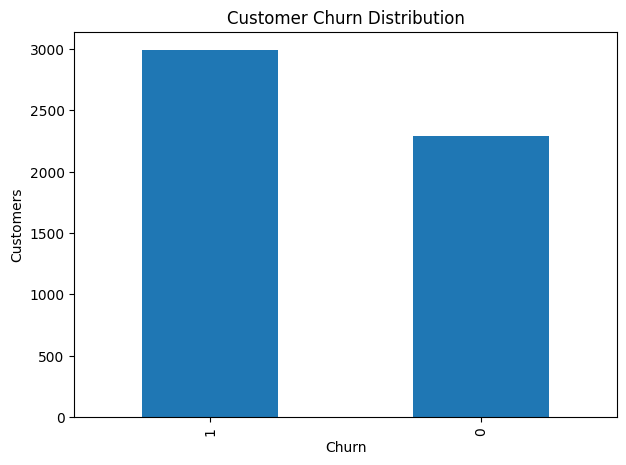

In [258]:
import matplotlib.pyplot as plt

y.value_counts().plot(
    kind='bar',
    figsize=(7,5)
)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Customers')
plt.show()

In [259]:
print(
    y.value_counts(normalize=True) * 100
)

Churn
1    56.615559
0    43.384441
Name: proportion, dtype: float64


In [260]:
customer_ml.groupby('Churn')[
    [
        'TotalRevenue',
        'TotalOrders',
        'TotalQuantity',
        'TotalProducts',
        'AverageOrderValue',
        'RecencyDays',
        'CustomerTenureDays',
        'TotalReturnedQuantity',
        'ReturnOrders',
        'ReturnOrderRate'
    ]
].mean().round(2)

,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,AverageOrderValue,RecencyDays,CustomerTenureDays,TotalReturnedQuantity,ReturnOrders,ReturnOrderRate
Churn,,,,,,,,,,
0,4720.18,9.26,2807.73,112.02,404.59,119.56,440.48,100.44,2.11,0.22
1,1159.73,3.05,773.78,45.45,356.02,273.92,424.39,43.41,0.62,0.19


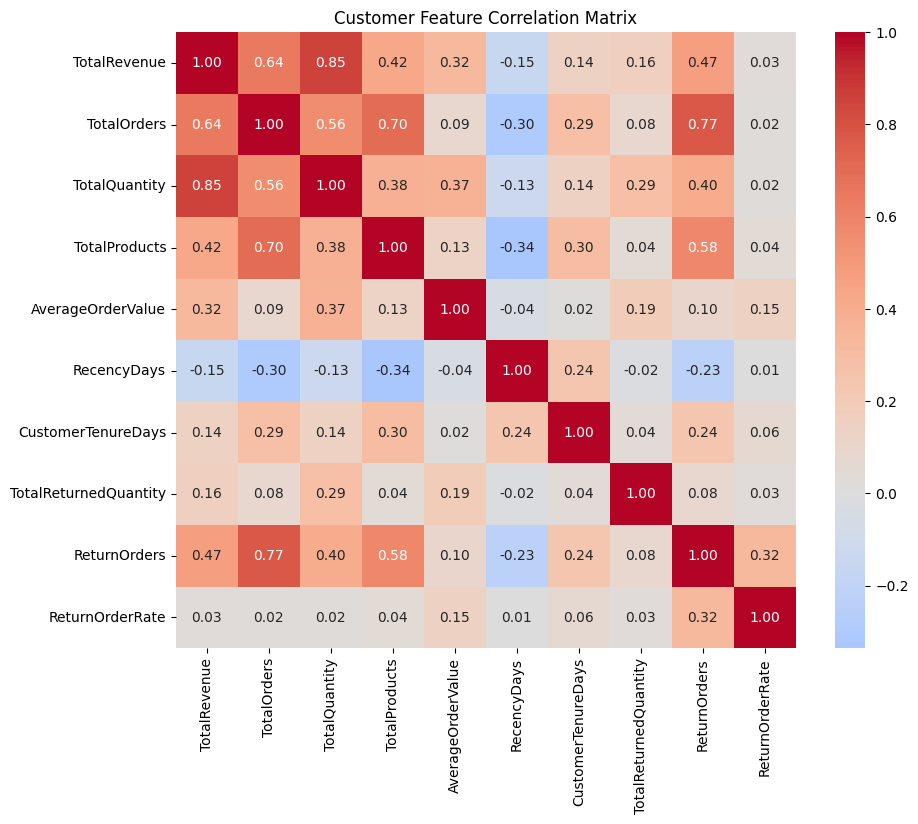

In [261]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

corr = X.corr()

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Customer Feature Correlation Matrix')
plt.show()

In [262]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
TotalRevenue,5283.0,2704.411973,12533.562018,0.0,323.730,803.880,2117.445000,484615.100000
TotalOrders,5283.0,5.744274,11.464724,1.0,1.000,3.000,6.000000,309.000000
TotalQuantity,5283.0,1656.198183,8140.723216,1.0,172.000,449.000,1243.000000,298662.000000
TotalProducts,5283.0,74.330305,104.963901,1.0,18.000,41.000,92.000000,2182.000000
AverageOrderValue,5283.0,377.090284,540.694852,0.0,179.205,283.495,420.493478,14844.766667
RecencyDays,5283.0,206.953246,175.141719,0.0,49.000,163.000,326.000000,647.000000
CustomerTenureDays,5283.0,431.372516,180.503060,0.0,311.000,473.000,586.000000,647.000000
TotalReturnedQuantity,5283.0,68.149347,1633.388972,0.0,0.000,0.000,7.000000,87563.000000
ReturnOrders,5283.0,1.263676,3.368723,0.0,0.000,0.000,1.000000,91.000000
ReturnOrderRate,5283.0,0.202773,0.353537,0.0,0.000,0.000,0.300000,4.000000


In [263]:
X.skew().sort_values(ascending=False)

TotalReturnedQuantity    47.341094
TotalRevenue             24.003863
TotalQuantity            20.293945
AverageOrderValue        13.460762
TotalOrders              11.071333
ReturnOrders             10.691131
TotalProducts             6.121706
ReturnOrderRate           2.792154
RecencyDays               0.664823
CustomerTenureDays       -0.632076
dtype: float64

In [264]:
X.corr().round(2)

,TotalRevenue,TotalOrders,TotalQuantity,TotalProducts,AverageOrderValue,RecencyDays,CustomerTenureDays,TotalReturnedQuantity,ReturnOrders,ReturnOrderRate
TotalRevenue,1.00,0.64,0.85,0.42,0.32,-0.15,0.14,0.16,0.47,0.03
TotalOrders,0.64,1.00,0.56,0.70,0.09,-0.30,0.29,0.08,0.77,0.02
TotalQuantity,0.85,0.56,1.00,0.38,0.37,-0.13,0.14,0.29,0.40,0.02
TotalProducts,0.42,0.70,0.38,1.00,0.13,-0.34,0.30,0.04,0.58,0.04
AverageOrderValue,0.32,0.09,0.37,0.13,1.00,-0.04,0.02,0.19,0.10,0.15
RecencyDays,-0.15,-0.30,-0.13,-0.34,-0.04,1.00,0.24,-0.02,-0.23,0.01
CustomerTenureDays,0.14,0.29,0.14,0.30,0.02,0.24,1.00,0.04,0.24,0.06
TotalReturnedQuantity,0.16,0.08,0.29,0.04,0.19,-0.02,0.04,1.00,0.08,0.03
ReturnOrders,0.47,0.77,0.40,0.58,0.10,-0.23,0.24,0.08,1.00,0.32
ReturnOrderRate,0.03,0.02,0.02,0.04,0.15,0.01,0.06,0.03,0.32,1.00


In [265]:
X.skew().sort_values(ascending=False)

TotalReturnedQuantity    47.341094
TotalRevenue             24.003863
TotalQuantity            20.293945
AverageOrderValue        13.460762
TotalOrders              11.071333
ReturnOrders             10.691131
TotalProducts             6.121706
ReturnOrderRate           2.792154
RecencyDays               0.664823
CustomerTenureDays       -0.632076
dtype: float64

In [266]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
TotalRevenue,5283.0,2704.411973,12533.562018,0.0,323.730,803.880,2117.445000,484615.100000
TotalOrders,5283.0,5.744274,11.464724,1.0,1.000,3.000,6.000000,309.000000
TotalQuantity,5283.0,1656.198183,8140.723216,1.0,172.000,449.000,1243.000000,298662.000000
TotalProducts,5283.0,74.330305,104.963901,1.0,18.000,41.000,92.000000,2182.000000
AverageOrderValue,5283.0,377.090284,540.694852,0.0,179.205,283.495,420.493478,14844.766667
RecencyDays,5283.0,206.953246,175.141719,0.0,49.000,163.000,326.000000,647.000000
CustomerTenureDays,5283.0,431.372516,180.503060,0.0,311.000,473.000,586.000000,647.000000
TotalReturnedQuantity,5283.0,68.149347,1633.388972,0.0,0.000,0.000,7.000000,87563.000000
ReturnOrders,5283.0,1.263676,3.368723,0.0,0.000,0.000,1.000000,91.000000
ReturnOrderRate,5283.0,0.202773,0.353537,0.0,0.000,0.000,0.300000,4.000000


In [267]:
import numpy as np

customer_ml_model['LogTotalRevenue'] = np.log1p(
    customer_ml_model['TotalRevenue']
)

customer_ml_model['LogTotalQuantity'] = np.log1p(
    customer_ml_model['TotalQuantity']
)

customer_ml_model['LogTotalOrders'] = np.log1p(
    customer_ml_model['TotalOrders']
)

customer_ml_model['LogTotalProducts'] = np.log1p(
    customer_ml_model['TotalProducts']
)

customer_ml_model['LogAverageOrderValue'] = np.log1p(
    customer_ml_model['AverageOrderValue']
)

customer_ml_model['LogTotalReturnedQuantity'] = np.log1p(
    customer_ml_model['TotalReturnedQuantity']
)

customer_ml_model['LogReturnOrders'] = np.log1p(
    customer_ml_model['ReturnOrders']
)

In [268]:
customer_ml_model[
    [
        'LogTotalRevenue',
        'LogTotalQuantity',
        'LogTotalOrders',
        'LogTotalProducts',
        'LogAverageOrderValue',
        'LogTotalReturnedQuantity',
        'LogReturnOrders'
    ]
].skew().sort_values(ascending=False)

LogTotalReturnedQuantity    1.525669
LogReturnOrders             1.430232
LogTotalOrders              1.058703
LogTotalRevenue             0.236187
LogTotalQuantity           -0.106439
LogAverageOrderValue       -0.198548
LogTotalProducts           -0.277524
dtype: float64

In [269]:
customer_ml[
    customer_ml['ReturnOrderRate'] > 1
][
    [
        'CustomerID',
        'TotalOrders',
        'ReturnOrders',
        'ReturnOrderRate'
    ]
].head(20)

,CustomerID,TotalOrders,ReturnOrders,ReturnOrderRate
144,12505.0,1,2.0,2.000000
161,12525.0,3,5.0,1.666667
168,12533.0,2,4.0,2.000000
214,12590.0,2,3.0,1.500000
346,12746.0,1,2.0,2.000000
367,12770.0,2,5.0,2.500000
391,12797.0,2,4.0,2.000000
401,12807.0,1,2.0,2.000000
403,12809.0,3,5.0,1.666667
499,12918.0,1,2.0,2.000000


In [270]:
(customer_ml['ReturnOrderRate'] > 1).sum()

np.int64(88)

In [271]:
customer_ml_model['ReturnQuantityRate'] = (
    customer_ml_model['TotalReturnedQuantity'] /
    customer_ml_model['TotalQuantity']
)

In [272]:
customer_ml_model['ReturnQuantityRate'].describe()

count    5283.00000
mean        0.02520
std         0.14488
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00786
max         3.00000
Name: ReturnQuantityRate, dtype: float64

In [273]:
print(
    "Infinite values:",
    np.isinf(
        customer_ml_model['ReturnQuantityRate']
    ).sum()
)

print(
    "Missing values:",
    customer_ml_model['ReturnQuantityRate'].isna().sum()
)

Infinite values: 0
Missing values: 0


In [274]:
from scipy.stats import mannwhitneyu
import pandas as pd

features_to_test = [
    'TotalRevenue',
    'TotalOrders',
    'TotalQuantity',
    'TotalProducts',
    'AverageOrderValue',
    'RecencyDays',
    'CustomerTenureDays',
    'TotalReturnedQuantity',
    'ReturnOrders',
    'ReturnQuantityRate'
]

results = []

for feature in features_to_test:

    retained = customer_ml_model.loc[
        customer_ml_model['Churn'] == 0,
        feature
    ]

    churned = customer_ml_model.loc[
        customer_ml_model['Churn'] == 1,
        feature
    ]

    statistic, p_value = mannwhitneyu(
        retained,
        churned,
        alternative='two-sided'
    )

    results.append({
        'Feature': feature,
        'RetainedMedian': retained.median(),
        'ChurnedMedian': churned.median(),
        'PValue': p_value
    })

stat_results = pd.DataFrame(results)

stat_results['Significant'] = (
    stat_results['PValue'] < 0.05
)

stat_results.sort_values('PValue')

,Feature,RetainedMedian,ChurnedMedian,PValue,Significant
5,RecencyDays,66.000000,287.00,1.648072e-237,True
1,TotalOrders,5.000000,2.00,9.559100e-219,True
0,TotalRevenue,1656.400000,495.98,2.496911e-200,True
2,TotalQuantity,925.000000,270.00,8.527117e-199,True
3,TotalProducts,72.000000,28.00,5.728565e-172,True
8,ReturnOrders,1.000000,0.00,1.792405e-94,True
7,TotalReturnedQuantity,2.000000,0.00,3.675996e-83,True
9,ReturnQuantityRate,0.001536,0.00,8.529558e-47,True
4,AverageOrderValue,313.340571,253.88,4.930751e-37,True
6,CustomerTenureDays,501.000000,458.00,3.823709e-09,True


In [275]:
customer_ml_model['ReturnQuantityRate'] = (
    customer_ml_model['TotalReturnedQuantity'] /
    customer_ml_model['TotalQuantity']
)

customer_ml_model['ReturnQuantityRate'].describe()

count    5283.00000
mean        0.02520
std         0.14488
min         0.00000
25%         0.00000
50%         0.00000
75%         0.00786
max         3.00000
Name: ReturnQuantityRate, dtype: float64

In [276]:
model_features = [
    'RecencyDays',
    'TotalOrders',
    'TotalRevenue',
    'TotalQuantity',
    'TotalProducts',
    'AverageOrderValue',
    'CustomerTenureDays',
    'TotalReturnedQuantity',
    'ReturnOrders',
    'ReturnQuantityRate'
]

X = customer_ml_model[model_features].copy()
y = customer_ml_model['Churn'].copy()


In [277]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (5283, 10)
y shape: (5283,)


,RecencyDays,TotalOrders,TotalRevenue,TotalQuantity,TotalProducts,AverageOrderValue,CustomerTenureDays,TotalReturnedQuantity,ReturnOrders,ReturnQuantityRate
0,234,12,77556.46,74285,27,6463.038333,634,74233.0,5.0,0.999300
1,38,6,4114.18,2418,107,685.696667,313,0.0,0.0,0.000000
2,157,4,1709.40,2497,25,427.350000,347,0.0,0.0,0.000000
3,316,3,2671.14,993,90,890.380000,498,5.0,1.0,0.005035
4,219,1,334.40,197,17,334.400000,219,0.0,0.0,0.000000


In [278]:
log_features = [
    'TotalRevenue',
    'TotalOrders',
    'TotalQuantity',
    'TotalProducts',
    'AverageOrderValue',
    'TotalReturnedQuantity',
    'ReturnOrders'
]

In [279]:
X_log = X.copy()

for feature in log_features:
    X_log['Log_' + feature] = np.log1p(X_log[feature])

In [280]:
X_transformed = pd.DataFrame(index=X.index)

X_transformed['RecencyDays'] = X['RecencyDays']

X_transformed['LogTotalOrders'] = np.log1p(
    X['TotalOrders']
)

X_transformed['LogTotalRevenue'] = np.log1p(
    X['TotalRevenue']
)

X_transformed['LogTotalQuantity'] = np.log1p(
    X['TotalQuantity']
)

X_transformed['LogTotalProducts'] = np.log1p(
    X['TotalProducts']
)

X_transformed['LogAverageOrderValue'] = np.log1p(
    X['AverageOrderValue']
)

X_transformed['CustomerTenureDays'] = X['CustomerTenureDays']

X_transformed['LogTotalReturnedQuantity'] = np.log1p(
    X['TotalReturnedQuantity']
)

X_transformed['LogReturnOrders'] = np.log1p(
    X['ReturnOrders']
)

X_transformed['ReturnQuantityRate'] = X['ReturnQuantityRate']

In [281]:
X_transformed.shape

(5283, 10)

In [282]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_transformed,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTraining churn distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting churn distribution:")
print(y_test.value_counts(normalize=True))

X_train: (4226, 10)
X_test: (1057, 10)

Training churn distribution:
Churn
1    0.566257
0    0.433743
Name: proportion, dtype: float64

Testing churn distribution:
Churn
1    0.565752
0    0.434248
Name: proportion, dtype: float64


In [283]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [284]:
y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [285]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))

Accuracy : 0.7569
Precision: 0.7685
Recall   : 0.8161
F1 Score : 0.7916
ROC-AUC  : 0.8103


In [286]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))


Classification Report:

              precision    recall  f1-score   support

           0       0.74      0.68      0.71       459
           1       0.77      0.82      0.79       598

    accuracy                           0.76      1057
   macro avg       0.75      0.75      0.75      1057
weighted avg       0.76      0.76      0.76      1057



In [287]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[312 147]
 [110 488]]


In [288]:
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': logistic_model.named_steps['model'].coef_[0]
})

coef_df['AbsCoefficient'] = coef_df['Coefficient'].abs()

coef_df = coef_df.sort_values(
    'AbsCoefficient',
    ascending=False
)

coef_df

,Feature,Coefficient,AbsCoefficient
1,LogTotalOrders,-0.904367,0.904367
0,RecencyDays,0.499093,0.499093
2,LogTotalRevenue,0.391974,0.391974
6,CustomerTenureDays,0.352542,0.352542
4,LogTotalProducts,-0.291096,0.291096
3,LogTotalQuantity,-0.220407,0.220407
5,LogAverageOrderValue,-0.207127,0.207127
8,LogReturnOrders,-0.140871,0.140871
9,ReturnQuantityRate,0.075196,0.075196
7,LogTotalReturnedQuantity,0.056040,0.056040


In [289]:
coef_df[['Feature', 'Coefficient']]

,Feature,Coefficient
1,LogTotalOrders,-0.904367
0,RecencyDays,0.499093
2,LogTotalRevenue,0.391974
6,CustomerTenureDays,0.352542
4,LogTotalProducts,-0.291096
3,LogTotalQuantity,-0.220407
5,LogAverageOrderValue,-0.207127
8,LogReturnOrders,-0.140871
9,ReturnQuantityRate,0.075196
7,LogTotalReturnedQuantity,0.056040


In [290]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=20,
    random_state=42
)

dt_model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,20
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [291]:
dt_pred = dt_model.predict(X_test)

dt_prob = dt_model.predict_proba(X_test)[:, 1]

In [292]:
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)
dt_auc = roc_auc_score(y_test, dt_prob)

print("Decision Tree")
print("--------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("ROC-AUC  :", round(dt_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Decision Tree
--------------------
Accuracy : 0.7351
Precision: 0.7304
Recall   : 0.8428
F1 Score : 0.7826
ROC-AUC  : 0.8076

Confusion Matrix:
[[273 186]
 [ 94 504]]


In [293]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=10,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [294]:
rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [295]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest")
print("--------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("ROC-AUC  :", round(rf_auc, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest
--------------------
Accuracy : 0.755
Precision: 0.7549
Recall   : 0.8395
F1 Score : 0.7949
ROC-AUC  : 0.815

Confusion Matrix:
[[296 163]
 [ 96 502]]


In [296]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Accuracy': [
        accuracy,
        dt_accuracy,
        rf_accuracy
    ],
    'Precision': [
        precision,
        dt_precision,
        rf_precision
    ],
    'Recall': [
        recall,
        dt_recall,
        rf_recall
    ],
    'F1': [
        f1,
        dt_f1,
        rf_f1
    ],
    'ROC-AUC': [
        roc_auc,
        dt_auc,
        rf_auc
    ]
})

results.sort_values(
    'ROC-AUC',
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.754967,0.754887,0.839465,0.794933,0.814986
1,Logistic Regression,0.756859,0.768504,0.816054,0.791565,0.810315
2,Decision Tree,0.735099,0.730435,0.842809,0.782609,0.807556


In [297]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

In [298]:
rf_param_dist = {
    'n_estimators': randint(200, 600),
    'max_depth': [None, 5, 8, 10, 12, 15],
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(2, 20),
    'max_features': ['sqrt', 'log2', None],
    'class_weight': [None, 'balanced']
}

In [ ]:
rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=rf_param_dist,
    n_iter=30,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


In [ ]:
print("Best parameters:")
print(rf_search.best_params_)

print("\nBest CV ROC-AUC:")
print(round(rf_search.best_score_, 4))

Best parameters:
{'class_weight': 'balanced', 'max_depth': 12, 'max_features': 'log2', 'min_samples_leaf': 14, 'min_samples_split': 10, 'n_estimators': 356}

Best CV ROC-AUC:
0.7994


In [ ]:
best_rf = rf_search.best_estimator_

tuned_rf_pred = best_rf.predict(X_test)

tuned_rf_prob = best_rf.predict_proba(X_test)[:, 1]

In [ ]:
print("Tuned Random Forest")
print("-------------------------")

print(
    "Accuracy :",
    round(accuracy_score(y_test, tuned_rf_pred), 4)
)

print(
    "Precision:",
    round(precision_score(y_test, tuned_rf_pred), 4)
)

print(
    "Recall   :",
    round(recall_score(y_test, tuned_rf_pred), 4)
)

print(
    "F1 Score :",
    round(f1_score(y_test, tuned_rf_pred), 4)
)

print(
    "ROC-AUC  :",
    round(roc_auc_score(y_test, tuned_rf_prob), 4)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_rf_pred))

Tuned Random Forest
-------------------------
Accuracy : 0.7512
Precision: 0.7796
Recall   : 0.7809
F1 Score : 0.7803
ROC-AUC  : 0.8142

Confusion Matrix:
[[327 132]
 [131 467]]


In [ ]:
rf_model

,n_estimators,300
,criterion,'gini'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,10
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [ ]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

feature_importance

,Feature,Importance
0,RecencyDays,0.304061
1,LogTotalRevenue,0.147370
2,LogTotalOrders,0.139088
3,LogTotalQuantity,0.123859
4,LogTotalProducts,0.099895
5,CustomerTenureDays,0.075483
6,LogAverageOrderValue,0.054154
7,ReturnQuantityRate,0.020550
8,LogTotalReturnedQuantity,0.017951
9,LogReturnOrders,0.017591


In [ ]:
feature_importance

,Feature,Importance
0,RecencyDays,0.304061
1,LogTotalRevenue,0.147370
2,LogTotalOrders,0.139088
3,LogTotalQuantity,0.123859
4,LogTotalProducts,0.099895
5,CustomerTenureDays,0.075483
6,LogAverageOrderValue,0.054154
7,ReturnQuantityRate,0.020550
8,LogTotalReturnedQuantity,0.017951
9,LogReturnOrders,0.017591


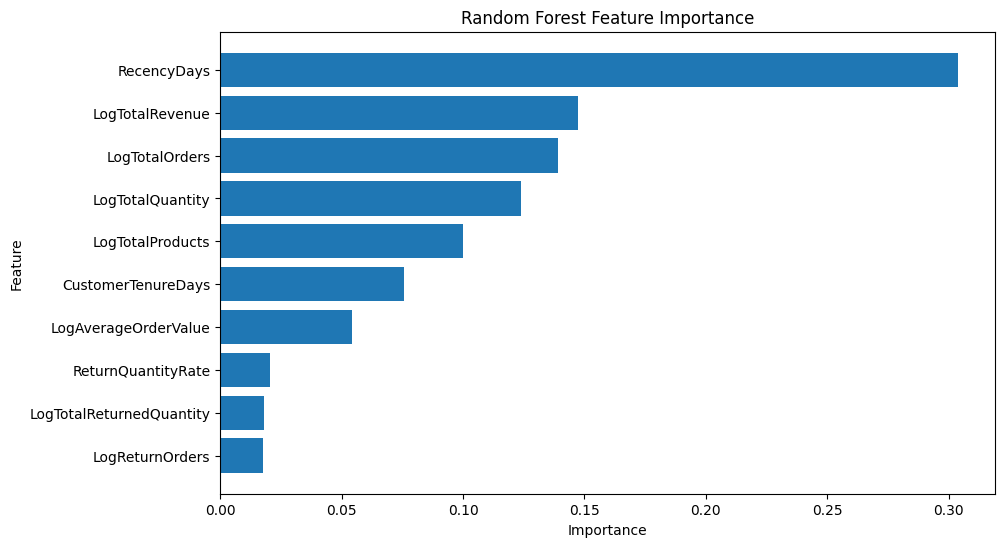

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Random Forest Feature Importance')

plt.gca().invert_yaxis()

plt.show()

In [ ]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [ ]:
perm_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'ImportanceMean': perm.importances_mean,
    'ImportanceStd': perm.importances_std
})

perm_importance = perm_importance.sort_values(
    'ImportanceMean',
    ascending=False
).reset_index(drop=True)

perm_importance

,Feature,ImportanceMean,ImportanceStd
0,RecencyDays,0.123582,0.008478
1,LogTotalOrders,0.013873,0.002959
2,LogTotalRevenue,0.008954,0.002377
3,LogTotalProducts,0.008109,0.002379
4,LogTotalQuantity,0.005240,0.001851
5,CustomerTenureDays,0.005210,0.002935
6,LogTotalReturnedQuantity,0.000357,0.000444
7,LogReturnOrders,0.000357,0.000326
8,ReturnQuantityRate,-0.000059,0.000445
9,LogAverageOrderValue,-0.000380,0.001421


In [ ]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(
    'Importance',
    ascending=False
).reset_index(drop=True)

feature_importance

,Feature,Importance
0,RecencyDays,0.304061
1,LogTotalRevenue,0.147370
2,LogTotalOrders,0.139088
3,LogTotalQuantity,0.123859
4,LogTotalProducts,0.099895
5,CustomerTenureDays,0.075483
6,LogAverageOrderValue,0.054154
7,ReturnQuantityRate,0.020550
8,LogTotalReturnedQuantity,0.017951
9,LogReturnOrders,0.017591


In [ ]:
perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

perm_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'ImportanceMean': perm.importances_mean,
    'ImportanceStd': perm.importances_std
}).sort_values(
    'ImportanceMean',
    ascending=False
).reset_index(drop=True)

perm_importance

,Feature,ImportanceMean,ImportanceStd
0,RecencyDays,0.123582,0.008478
1,LogTotalOrders,0.013873,0.002959
2,LogTotalRevenue,0.008954,0.002377
3,LogTotalProducts,0.008109,0.002379
4,LogTotalQuantity,0.005240,0.001851
5,CustomerTenureDays,0.005210,0.002935
6,LogTotalReturnedQuantity,0.000357,0.000444
7,LogReturnOrders,0.000357,0.000326
8,ReturnQuantityRate,-0.000059,0.000445
9,LogAverageOrderValue,-0.000380,0.001421


In [ ]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\hp\AppData\Local\Programs\Python\Python311\python.exe
3.11.8 (tags/v3.11.8:db85d51, Feb  6 2024, 22:03:32) [MSC v.1937 64 bit (AMD64)]


In [ ]:
import shap
print(shap.__version__)
print(shap.__file__)

0.51.0
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\shap\__init__.py


In [ ]:
import numpy
import pandas
import sklearn

print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Scikit-learn:", sklearn.__version__)

NumPy: 2.3.1
Pandas: 2.3.0
Scikit-learn: 1.7.2


In [ ]:
import shap

explainer = shap.TreeExplainer(rf_model)

shap_values = explainer.shap_values(X_test)

print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(1057, 10, 2)


In [ ]:
shap_values_churn = shap_values[:, :, 1]

print(shap_values_churn.shape)

(1057, 10)


In [ ]:
shap_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'MeanAbsSHAP': np.abs(shap_values_churn).mean(axis=0)
}).sort_values(
    'MeanAbsSHAP',
    ascending=False
).reset_index(drop=True)

shap_importance

,Feature,MeanAbsSHAP
0,RecencyDays,0.110008
1,LogTotalOrders,0.045755
2,LogTotalRevenue,0.041725
3,LogTotalQuantity,0.038833
4,LogTotalProducts,0.037064
5,CustomerTenureDays,0.030062
6,LogAverageOrderValue,0.011164
7,LogReturnOrders,0.004901
8,ReturnQuantityRate,0.004482
9,LogTotalReturnedQuantity,0.004182


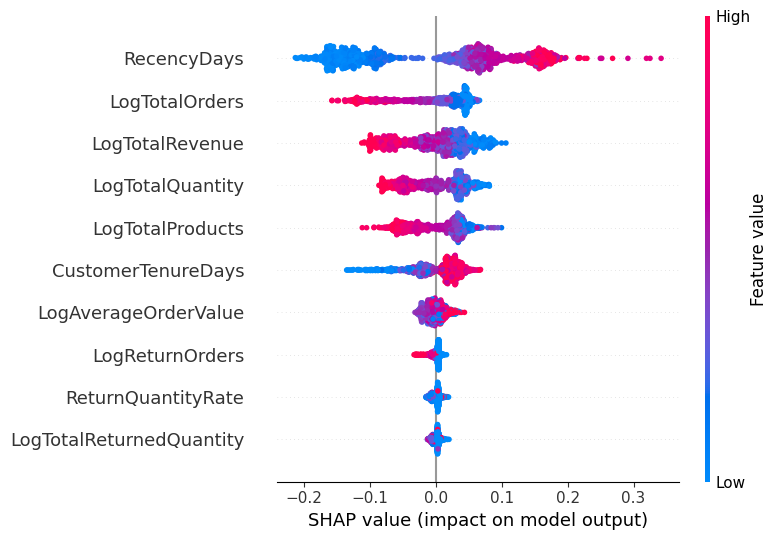

In [ ]:
shap.summary_plot(
    shap_values_churn,
    X_test
)

In [ ]:
customer_index = 0

customer_shap = pd.DataFrame({
    'Feature': X_test.columns,
    'SHAP': shap_values_churn[customer_index]
})

customer_shap['AbsSHAP'] = customer_shap['SHAP'].abs()

customer_shap = customer_shap.sort_values(
    'AbsSHAP',
    ascending=False
)

customer_shap

,Feature,SHAP,AbsSHAP
2,LogTotalRevenue,0.046448,0.046448
3,LogTotalQuantity,0.037806,0.037806
4,LogTotalProducts,0.032148,0.032148
1,LogTotalOrders,0.030019,0.030019
6,CustomerTenureDays,0.028939,0.028939
0,RecencyDays,0.026229,0.026229
5,LogAverageOrderValue,-0.010386,0.010386
8,LogReturnOrders,0.003189,0.003189
9,ReturnQuantityRate,0.001550,0.001550
7,LogTotalReturnedQuantity,0.001370,0.001370


In [ ]:
customer_index = 0

customer_id = X_test.index[customer_index]

# Customer information
customer_info = customer_df.loc[customer_id]

# Churn probability
churn_probability = rf_model.predict_proba(
    X_test.iloc[[customer_index]]
)[0][1]

# Actual churn
actual_churn = y_test.iloc[customer_index]

# Revenue
revenue = customer_info['TotalRevenue']

# Revenue at risk
revenue_at_risk = revenue * churn_probability

print("Customer ID:", customer_info['CustomerID'])
print("Customer Segment:", customer_info['CustomerSegment'])
print("Actual Churn:", actual_churn)
print("Churn Probability:", round(churn_probability * 100, 2), "%")
print("Total Revenue:", round(revenue, 2))
print("Revenue at Risk:", round(revenue_at_risk, 2))

Customer ID: 15361.0
Customer Segment: At-Risk
Actual Churn: 1
Churn Probability: 76.4 %
Total Revenue: 689.07
Revenue at Risk: 526.43


In [ ]:
# Churn probability for every customer in the test set
churn_probability = rf_model.predict_proba(X_test)[:, 1]

# Predicted churn class
churn_prediction = rf_model.predict(X_test)

customer_risk = customer_df.loc[X_test.index, [
    'CustomerID',
    'CustomerSegment',
    'TotalRevenue'
]].copy()

customer_risk['ChurnProbability'] = churn_probability
customer_risk['ChurnPrediction'] = churn_prediction

customer_risk.head()

,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,ChurnPrediction
2984,15361.0,At-Risk,689.07,0.763967,1
5194,17597.0,At-Risk,3484.09,0.688027,1
3772,16156.0,VIP / High-Value Loyal,6218.18,0.686142,1
5029,17428.0,VIP / High-Value Loyal,31819.76,0.821028,1
5178,17581.0,VIP / High-Value Loyal,18757.75,0.943005,1


In [ ]:
# Churn probability for every customer in the test set
churn_probability = rf_model.predict_proba(X_test)[:, 1]

# Predicted churn class
churn_prediction = rf_model.predict(X_test)

customer_risk = customer_df.loc[X_test.index, [
    'CustomerID',
    'CustomerSegment',
    'TotalRevenue'
]].copy()

customer_risk['ChurnProbability'] = churn_probability
customer_risk['ChurnPrediction'] = churn_prediction

customer_risk.head()

,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,ChurnPrediction
2984,15361.0,At-Risk,689.07,0.763967,1
5194,17597.0,At-Risk,3484.09,0.688027,1
3772,16156.0,VIP / High-Value Loyal,6218.18,0.686142,1
5029,17428.0,VIP / High-Value Loyal,31819.76,0.821028,1
5178,17581.0,VIP / High-Value Loyal,18757.75,0.943005,1


In [ ]:
customer_risk['RevenueAtRisk'] = (
    customer_risk['TotalRevenue'] *
    customer_risk['ChurnProbability']
)

customer_risk.head()

,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,ChurnPrediction,RevenueAtRisk
2984,15361.0,At-Risk,689.07,0.763967,1,526.426917
5194,17597.0,At-Risk,3484.09,0.688027,1,2397.148072
3772,16156.0,VIP / High-Value Loyal,6218.18,0.686142,1,4266.555290
5029,17428.0,VIP / High-Value Loyal,31819.76,0.821028,1,26124.902521
5178,17581.0,VIP / High-Value Loyal,18757.75,0.943005,1,17688.648412


In [ ]:
def risk_level(probability):
    if probability >= 0.75:
        return 'Critical'
    elif probability >= 0.50:
        return 'High'
    elif probability >= 0.30:
        return 'Medium'
    else:
        return 'Low'


customer_risk['RiskLevel'] = (
    customer_risk['ChurnProbability']
    .apply(risk_level)
)

customer_risk.head()

,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,ChurnPrediction,RevenueAtRisk,RiskLevel
2984,15361.0,At-Risk,689.07,0.763967,1,526.426917,Critical
5194,17597.0,At-Risk,3484.09,0.688027,1,2397.148072,High
3772,16156.0,VIP / High-Value Loyal,6218.18,0.686142,1,4266.555290,High
5029,17428.0,VIP / High-Value Loyal,31819.76,0.821028,1,26124.902521,Critical
5178,17581.0,VIP / High-Value Loyal,18757.75,0.943005,1,17688.648412,Critical


In [ ]:
top_revenue_risk = customer_risk.sort_values(
    'RevenueAtRisk',
    ascending=False
)

top_revenue_risk.head(20)

,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,ChurnPrediction,RevenueAtRisk,RiskLevel
5050,17450.0,VIP / High-Value Loyal,246973.090,0.729895,1,180264.364925,High
2685,15061.0,VIP / High-Value Loyal,137818.520,0.740546,1,102060.904219,High
4037,16422.0,VIP / High-Value Loyal,63651.470,0.881101,1,56083.374845,Critical
1050,13408.0,VIP / High-Value Loyal,51733.462,0.832040,1,43044.311259,Critical
2538,14911.0,VIP / High-Value Loyal,295972.630,0.128509,0,38035.040729,Low
4364,16754.0,VIP / High-Value Loyal,67502.470,0.480694,0,32448.038866,Medium
1666,14031.0,VIP / High-Value Loyal,40999.170,0.718671,1,29464.933714,High
728,13078.0,VIP / High-Value Loyal,29532.450,0.938800,1,27725.058663,Critical
5029,17428.0,VIP / High-Value Loyal,31819.760,0.821028,1,26124.902521,Critical
4984,17381.0,VIP / High-Value Loyal,40002.370,0.565965,1,22639.948707,High


In [ ]:
total_revenue_at_risk = customer_risk['RevenueAtRisk'].sum()

print(
    "Estimated Revenue at Risk:",
    round(total_revenue_at_risk, 2)
)

Estimated Revenue at Risk: 1966964.25


In [ ]:
risk_summary = customer_risk.groupby(
    'RiskLevel'
).agg(
    Customers=('CustomerID', 'count'),
    TotalRevenue=('TotalRevenue', 'sum'),
    RevenueAtRisk=('RevenueAtRisk', 'sum'),
    AvgChurnProbability=('ChurnProbability', 'mean')
).reset_index()

risk_summary['AvgChurnProbability'] = (
    risk_summary['AvgChurnProbability'] * 100
).round(2)

risk_summary['TotalRevenue'] = (
    risk_summary['TotalRevenue'].round(2)
)

risk_summary['RevenueAtRisk'] = (
    risk_summary['RevenueAtRisk'].round(2)
)

risk_summary

,RiskLevel,Customers,TotalRevenue,RevenueAtRisk,AvgChurnProbability
0,Critical,303,939564.11,806669.01,85.25
1,High,362,1256158.14,832018.05,63.62
2,Low,200,1245225.77,120363.19,15.41
3,Medium,192,487531.13,207914.01,41.31


In [ ]:
customer_risk['RevenueRiskPercent'] = (
    customer_risk['RevenueAtRisk'] /
    customer_risk['TotalRevenue'].replace(0, np.nan)
) * 100

customer_risk['RetentionPriorityScore'] = (
    customer_risk['ChurnProbability'] * 0.6 +
    (
        customer_risk['RevenueAtRisk'] /
        customer_risk['RevenueAtRisk'].max()
    ) * 0.4
)

customer_risk['RetentionPriorityScore'] = (
    customer_risk['RetentionPriorityScore'] * 100
).round(2)

In [ ]:
def retention_priority(score):
    if score >= 70:
        return 'P1 - Immediate Action'
    elif score >= 50:
        return 'P2 - High Priority'
    elif score >= 30:
        return 'P3 - Monitor'
    else:
        return 'P4 - Low Priority'


customer_risk['RetentionPriority'] = (
    customer_risk['RetentionPriorityScore']
    .apply(retention_priority)
)

In [ ]:
customer_risk[
    [
        'CustomerID',
        'CustomerSegment',
        'TotalRevenue',
        'ChurnProbability',
        'RevenueAtRisk',
        'RiskLevel',
        'RetentionPriorityScore',
        'RetentionPriority'
    ]
].sort_values(
    'RetentionPriorityScore',
    ascending=False
).head(20)

,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,RevenueAtRisk,RiskLevel,RetentionPriorityScore,RetentionPriority
5050,17450.0,VIP / High-Value Loyal,246973.090,0.729895,180264.364925,High,83.79,P1 - Immediate Action
2685,15061.0,VIP / High-Value Loyal,137818.520,0.740546,102060.904219,High,67.08,P2 - High Priority
4037,16422.0,VIP / High-Value Loyal,63651.470,0.881101,56083.374845,Critical,65.31,P2 - High Priority
728,13078.0,VIP / High-Value Loyal,29532.450,0.938800,27725.058663,Critical,62.48,P2 - High Priority
5178,17581.0,VIP / High-Value Loyal,18757.750,0.943005,17688.648412,Critical,60.51,P2 - High Priority
372,12720.0,VIP / High-Value Loyal,8260.670,0.967646,7993.407488,Critical,59.83,P2 - High Priority
4846,17243.0,VIP / High-Value Loyal,20889.860,0.921635,19252.819903,Critical,59.57,P2 - High Priority
963,13316.0,VIP / High-Value Loyal,13191.570,0.945154,12468.061997,Critical,59.48,P2 - High Priority
1050,13408.0,VIP / High-Value Loyal,51733.462,0.832040,43044.311259,Critical,59.47,P2 - High Priority
622,12971.0,VIP / High-Value Loyal,15972.790,0.925949,14789.982935,Critical,58.84,P2 - High Priority


In [ ]:
# Churn probability for every customer in the test set
churn_probability = rf_model.predict_proba(X_test)[:, 1]

# Predicted churn class
churn_prediction = rf_model.predict(X_test)

customer_risk = customer_df.loc[X_test.index, [
    'CustomerID',
    'CustomerSegment',
    'TotalRevenue'
]].copy()

customer_risk['ChurnProbability'] = churn_probability
customer_risk['ChurnPrediction'] = churn_prediction

customer_risk.head()

,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,ChurnPrediction
2984,15361.0,At-Risk,689.07,0.763967,1
5194,17597.0,At-Risk,3484.09,0.688027,1
3772,16156.0,VIP / High-Value Loyal,6218.18,0.686142,1
5029,17428.0,VIP / High-Value Loyal,31819.76,0.821028,1
5178,17581.0,VIP / High-Value Loyal,18757.75,0.943005,1


In [ ]:
# ==========================================
# RETENTION INTELLIGENCE - COMPLETE SETUP
# ==========================================

# 1. Recreate customer risk table
customer_risk = customer_df.loc[
    X_test.index,
    [
        'CustomerID',
        'CustomerSegment',
        'TotalRevenue'
    ]
].copy()

# 2. Churn probability
customer_risk['ChurnProbability'] = (
    rf_model.predict_proba(X_test)[:, 1]
)

# 3. Churn prediction
customer_risk['ChurnPrediction'] = (
    rf_model.predict(X_test)
)

# 4. Revenue at Risk
customer_risk['RevenueAtRisk'] = (
    customer_risk['TotalRevenue'] *
    customer_risk['ChurnProbability']
)

# 5. Risk Level
def risk_level(probability):
    if probability >= 0.75:
        return 'Critical'
    elif probability >= 0.50:
        return 'High'
    elif probability >= 0.30:
        return 'Medium'
    else:
        return 'Low'

customer_risk['RiskLevel'] = (
    customer_risk['ChurnProbability']
    .apply(risk_level)
)

# 6. Retention Priority Score
customer_risk['RetentionPriorityScore'] = (
    customer_risk['ChurnProbability'] * 0.6
    +
    (
        customer_risk['RevenueAtRisk'] /
        customer_risk['RevenueAtRisk'].max()
    ) * 0.4
) * 100

customer_risk['RetentionPriorityScore'] = (
    customer_risk['RetentionPriorityScore'].round(2)
)

# 7. Retention Priority
def retention_priority(score):
    if score >= 70:
        return 'P1 - Immediate Action'
    elif score >= 50:
        return 'P2 - High Priority'
    elif score >= 30:
        return 'P3 - Monitor'
    else:
        return 'P4 - Low Priority'

customer_risk['RetentionPriority'] = (
    customer_risk['RetentionPriorityScore']
    .apply(retention_priority)
)

# 8. Recommended Action
def retention_action(row):

    segment = row['CustomerSegment']
    risk = row['RiskLevel']

    if risk == 'Critical' and segment == 'VIP / High-Value Loyal':
        return 'Personalized VIP retention offer'

    elif risk == 'Critical':
        return 'Immediate retention campaign'

    elif risk == 'High' and segment == 'At-Risk':
        return 'Targeted discount / loyalty offer'

    elif risk == 'High':
        return 'Personalized re-engagement campaign'

    elif risk == 'Medium':
        return 'Email recommendation / promotional campaign'

    else:
        return 'Regular loyalty engagement'


customer_risk['RecommendedAction'] = (
    customer_risk.apply(retention_action, axis=1)
)

print("Customer risk table created successfully.")
print("Shape:", customer_risk.shape)

customer_risk.head()

Customer risk table created successfully.
Shape: (1057, 10)


,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,ChurnPrediction,RevenueAtRisk,RiskLevel,RetentionPriorityScore,RetentionPriority,RecommendedAction
2984,15361.0,At-Risk,689.07,0.763967,1,526.426917,Critical,45.95,P3 - Monitor,Immediate retention campaign
5194,17597.0,At-Risk,3484.09,0.688027,1,2397.148072,High,41.81,P3 - Monitor,Targeted discount / loyalty offer
3772,16156.0,VIP / High-Value Loyal,6218.18,0.686142,1,4266.555290,High,42.12,P3 - Monitor,Personalized re-engagement campaign
5029,17428.0,VIP / High-Value Loyal,31819.76,0.821028,1,26124.902521,Critical,55.06,P2 - High Priority,Personalized VIP retention offer
5178,17581.0,VIP / High-Value Loyal,18757.75,0.943005,1,17688.648412,Critical,60.51,P2 - High Priority,Personalized VIP retention offer


In [ ]:
top_priority_customers = customer_risk.sort_values(
    'RetentionPriorityScore',
    ascending=False
)

top_priority_customers[
    [
        'CustomerID',
        'CustomerSegment',
        'TotalRevenue',
        'ChurnProbability',
        'RevenueAtRisk',
        'RiskLevel',
        'RetentionPriorityScore',
        'RetentionPriority',
        'RecommendedAction'
    ]
].head(20)

,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,RevenueAtRisk,RiskLevel,RetentionPriorityScore,RetentionPriority,RecommendedAction
5050,17450.0,VIP / High-Value Loyal,246973.090,0.729895,180264.364925,High,83.79,P1 - Immediate Action,Personalized re-engagement campaign
2685,15061.0,VIP / High-Value Loyal,137818.520,0.740546,102060.904219,High,67.08,P2 - High Priority,Personalized re-engagement campaign
4037,16422.0,VIP / High-Value Loyal,63651.470,0.881101,56083.374845,Critical,65.31,P2 - High Priority,Personalized VIP retention offer
728,13078.0,VIP / High-Value Loyal,29532.450,0.938800,27725.058663,Critical,62.48,P2 - High Priority,Personalized VIP retention offer
5178,17581.0,VIP / High-Value Loyal,18757.750,0.943005,17688.648412,Critical,60.51,P2 - High Priority,Personalized VIP retention offer
372,12720.0,VIP / High-Value Loyal,8260.670,0.967646,7993.407488,Critical,59.83,P2 - High Priority,Personalized VIP retention offer
4846,17243.0,VIP / High-Value Loyal,20889.860,0.921635,19252.819903,Critical,59.57,P2 - High Priority,Personalized VIP retention offer
963,13316.0,VIP / High-Value Loyal,13191.570,0.945154,12468.061997,Critical,59.48,P2 - High Priority,Personalized VIP retention offer
1050,13408.0,VIP / High-Value Loyal,51733.462,0.832040,43044.311259,Critical,59.47,P2 - High Priority,Personalized VIP retention offer
622,12971.0,VIP / High-Value Loyal,15972.790,0.925949,14789.982935,Critical,58.84,P2 - High Priority,Personalized VIP retention offer


In [ ]:
priority_summary = customer_risk.groupby(
    'RetentionPriority'
).agg(
    Customers=('CustomerID', 'count'),
    TotalRevenue=('TotalRevenue', 'sum'),
    RevenueAtRisk=('RevenueAtRisk', 'sum'),
    AvgChurnProbability=('ChurnProbability', 'mean')
).reset_index()

priority_summary['AvgChurnProbability'] = (
    priority_summary['AvgChurnProbability'] * 100
).round(2)

priority_summary['TotalRevenue'] = (
    priority_summary['TotalRevenue'].round(2)
)

priority_summary['RevenueAtRisk'] = (
    priority_summary['RevenueAtRisk'].round(2)
)

priority_summary

,RetentionPriority,Customers,TotalRevenue,RevenueAtRisk,AvgChurnProbability
0,P1 - Immediate Action,1,246973.09,180264.36,72.99
1,P2 - High Priority,191,858882.11,738358.95,89.32
2,P3 - Monitor,479,1215849.44,779890.24,66.85
3,P4 - Low Priority,386,1606774.51,268450.70,27.77


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

xgb_probability = xgb_model.predict_proba(X_test)[:, 1]
xgb_prediction = (xgb_probability >= 0.5).astype(int)


In [ ]:
xgb_prediction 

array([1, 1, 1, ..., 1, 1, 1], shape=(1057,))

In [ ]:
xgb_probability

array([0.7206119 , 0.6918681 , 0.5126106 , ..., 0.9671348 , 0.71861595,
       0.955554  ], shape=(1057,), dtype=float32)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1 Score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, xgb_probability), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy : 0.7569
Precision: 0.7685
Recall   : 0.8161
F1 Score : 0.7916
ROC-AUC  : 0.8005

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.68      0.71       459
           1       0.77      0.82      0.79       598

    accuracy                           0.76      1057
   macro avg       0.75      0.75      0.75      1057
weighted avg       0.76      0.76      0.76      1057

Confusion Matrix:
[[312 147]
 [110 488]]


In [ ]:
customer_risk.shape


(1057, 10)

In [ ]:

customer_risk.columns.tolist()


['CustomerID',
 'CustomerSegment',
 'TotalRevenue',
 'ChurnProbability',
 'ChurnPrediction',
 'RevenueAtRisk',
 'RiskLevel',
 'RetentionPriorityScore',
 'RetentionPriority',
 'RecommendedAction']

In [ ]:
customer_risk.head()


,CustomerID,CustomerSegment,TotalRevenue,ChurnProbability,ChurnPrediction,RevenueAtRisk,RiskLevel,RetentionPriorityScore,RetentionPriority,RecommendedAction
2984,15361.0,At-Risk,689.07,0.763967,1,526.426917,Critical,45.95,P3 - Monitor,Immediate retention campaign
5194,17597.0,At-Risk,3484.09,0.688027,1,2397.148072,High,41.81,P3 - Monitor,Targeted discount / loyalty offer
3772,16156.0,VIP / High-Value Loyal,6218.18,0.686142,1,4266.555290,High,42.12,P3 - Monitor,Personalized re-engagement campaign
5029,17428.0,VIP / High-Value Loyal,31819.76,0.821028,1,26124.902521,Critical,55.06,P2 - High Priority,Personalized VIP retention offer
5178,17581.0,VIP / High-Value Loyal,18757.75,0.943005,1,17688.648412,Critical,60.51,P2 - High Priority,Personalized VIP retention offer
